# ATR-FTIR *Pinus pinaster* / *Fusarium circinatum*: classifiers on raw and second-derivative spectra, by spectral region

Compares classifiers that separate infected from control plants, trained on the pooled asymptomatic window (T1–T5) so that the timepoint of a new plant does not need to be known. Features are selected with mutual information and Pearson correlation.

The whole pipeline (feature selection, cross-validation, testing) runs for the raw absorbance (`absorbance_raw`) and for the second derivative (`second_derivative_raw`), each in three spectral regions (Combined, Fingerprint, Stretching). That makes six combinations of spectrum type and region. The train/test split is made once, at the level of biological samples: 80/20 within T1–T5, with everything from T0, T6 and T7 kept for testing.

There is one comparison chart per spectrum type, plus a chart that puts raw and second derivative side by side.

## Imports and paths

Libraries, random seeds, the paths `BASE_DIR`, `DATA_FILE` and `OUTPUT_DIR`, and the constants shared by the later cells (wavenumber windows and the list of timepoints).

In [1]:
%%time
import logging
import os
import random
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
%matplotlib inline
from lightgbm import LGBMClassifier
from matplotlib.patches import Patch
from scikeras.wrappers import KerasClassifier
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.cross_decomposition import PLSRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             matthews_corrcoef, precision_score)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.layers import (BatchNormalization, Conv1D, Dense, Dropout,
                                     GlobalAveragePooling1D, MaxPooling1D)
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['LOKY_MAX_CPU_COUNT'] = str(max(1, os.cpu_count() - 1))
tf.get_logger().setLevel('ERROR')
logging.getLogger('tensorflow').setLevel(logging.ERROR)

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['TF_DETERMINISTIC_OPS'] = '1'
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

BASE_DIR = r'C:/Users/MCL/Desktop/ML_ATR_FTIR_Spectra_Ppinaster'
DATA_FILE = os.path.join(BASE_DIR, 'Outputs', 'Spectra_Data', 'Full_data_infection_status_per_timepoint.csv')
OUTPUT_DIR = os.path.join(BASE_DIR, 'Outputs', 'Plots', '2_MI_Pearson_ML_Raw_2Derivative_Region_Comparison')
os.makedirs(OUTPUT_DIR, exist_ok=True)

FINGERPRINT = (800, 1800)
STRETCHING = (2800, 3800)
ALL_TIMEPOINTS = ['T0', 'T1', 'T2', 'T3', 'T4', 'T5', 'T6', 'T7']

CPU times: total: 6.52 s
Wall time: 8.47 s


## Load data

Reads `Full_data_infection_status_per_timepoint.csv` into `df`. All timepoints (T0–T7) are kept, and the region cut happens later, once per region. The table has both `absorbance_raw` and `second_derivative_raw`, the two spectrum types compared here.

In [2]:
%%time
df = pd.read_csv(DATA_FILE)
df

CPU times: total: 3.64 s
Wall time: 3.65 s


,wavenumber,sample_name,infection_status,trial,status,timepoint,sample_num,replicate,absorbance_raw,second_derivative_raw
0,3799.00,Pp_E1_T0_CT_01_1,CONTROL,E1,CT,T0,1,1,0.010270,3.465510e-06
1,3796.94,Pp_E1_T0_CT_01_1,CONTROL,E1,CT,T0,1,1,0.010417,-4.339472e-06
2,3794.88,Pp_E1_T0_CT_01_1,CONTROL,E1,CT,T0,1,1,0.010393,-2.234537e-05
3,3792.82,Pp_E1_T0_CT_01_1,CONTROL,E1,CT,T0,1,1,0.010320,-2.073846e-05
4,3790.76,Pp_E1_T0_CT_01_1,CONTROL,E1,CT,T0,1,1,0.010300,-2.432541e-07
...,...,...,...,...,...,...,...,...,...,...
2968483,809.22,Pp_E3_T7_FC_30_2,FUSARIUM,E3,FC,T7,30,2,0.188181,-1.124293e-04
2968484,807.16,Pp_E3_T7_FC_30_2,FUSARIUM,E3,FC,T7,30,2,0.189427,-1.196793e-04
2968485,805.10,Pp_E3_T7_FC_30_2,FUSARIUM,E3,FC,T7,30,2,0.190775,-1.235324e-04
2968486,803.04,Pp_E3_T7_FC_30_2,FUSARIUM,E3,FC,T7,30,2,0.192078,-1.225354e-04


## Sample IDs and replicates

`sample_name2` is `sample_name` without the trailing replicate digit, so replicates of the same biological sample share one ID. It is created once on `df`, and every table derived from `df` inherits it.

In [3]:
%%time
df['sample_name2'] = df['sample_name'].str.replace(r'_\d$', '', regex=True)

print("Replicates per biological sample (sample_name2):")
readings = (df.drop_duplicates(subset=['sample_name', 'wavenumber'])
            .groupby('sample_name2')['sample_name'].nunique())
print(readings.describe())
print(f"Total unique biological samples (sample_name2): {df['sample_name2'].nunique()}")

Replicates per biological sample (sample_name2):
count    1527.0
mean        2.0
std         0.0
min         2.0
25%         2.0
50%         2.0
75%         2.0
max         2.0
Name: sample_name, dtype: float64
Total unique biological samples (sample_name2): 1527
CPU times: total: 4.47 s
Wall time: 4.5 s


## Train/test split

Biological samples (`sample_name2`) are split 80/20 within T1–T5, stratified by infection status, trial and timepoint. If any stratum has fewer than 2 samples, the stratification falls back to status and trial, and then to status alone. Every sample from T0, T6 and T7 goes to the test set.

The split is made once and used for both spectrum types and all three regions, so every combination is tested on the same samples. Two assertions check that train and test share no samples and that nothing from the non-trainable timepoints ended up in training.

In [4]:
%%time
TEST_SIZE = 0.20
TRAIN_ELIGIBLE_TIMEPOINTS = ['T1', 'T2', 'T3', 'T4', 'T5']

sample_meta = (df.drop_duplicates(subset='sample_name2')
               [['sample_name2', 'trial', 'infection_status', 'timepoint']]
               .reset_index(drop=True))

splittable_meta = sample_meta[sample_meta['timepoint'].isin(TRAIN_ELIGIBLE_TIMEPOINTS)]
non_splittable_meta = sample_meta[~sample_meta['timepoint'].isin(TRAIN_ELIGIBLE_TIMEPOINTS)]


def make_strat_key(df_meta, cols):
    return df_meta[cols].astype(str).agg('_'.join, axis=1)


strat_cols = ['infection_status', 'trial', 'timepoint']
strat_key = make_strat_key(splittable_meta, strat_cols)
min_count = strat_key.value_counts().min()

if min_count < 2:
    print(f"Warning: stratifying by status, trial and timepoint would leave a group with only "
          f"{min_count} sample(s). Falling back to status and trial.")
    strat_cols = ['infection_status', 'trial']
    strat_key = make_strat_key(splittable_meta, strat_cols)
    min_count = strat_key.value_counts().min()

if min_count < 2:
    print(f"Warning: stratifying by status and trial would leave a group with only "
          f"{min_count} sample(s). Falling back to status only.")
    strat_cols = ['infection_status']
    strat_key = make_strat_key(splittable_meta, strat_cols)

train_samples_list, test_samples_from_split_list = train_test_split(
    splittable_meta['sample_name2'], test_size=TEST_SIZE, random_state=SEED,
    stratify=strat_key)

train_samples = set(train_samples_list)
test_samples = set(test_samples_from_split_list) | set(non_splittable_meta['sample_name2'])

print(f"Train: {len(train_samples)} unique samples, all from {TRAIN_ELIGIBLE_TIMEPOINTS}")
print(f"Test: {len(test_samples)} unique samples (20% of {TRAIN_ELIGIBLE_TIMEPOINTS} plus "
      f"every sample from {sorted(non_splittable_meta['timepoint'].unique())})")

overlap = train_samples & test_samples
assert len(overlap) == 0, (
    f"{len(overlap)} sample_name2 values are in both train_samples and test_samples "
    f"(replicate leakage between train and test)."
)
print("Train and test samples are disjoint.")

not_fully_in_test = non_splittable_meta[~non_splittable_meta['sample_name2'].isin(test_samples)]
assert len(not_fully_in_test) == 0, (
    f"{len(not_fully_in_test)} samples from non-trainable timepoints are missing from test_samples."
)
print(f"All samples from timepoints outside {TRAIN_ELIGIBLE_TIMEPOINTS} are in the test set.")

Train: 764 unique samples, all from ['T1', 'T2', 'T3', 'T4', 'T5']
Test: 763 unique samples (20% of ['T1', 'T2', 'T3', 'T4', 'T5'] plus every sample from ['T0', 'T6', 'T7'])
Train and test samples are disjoint.
All samples from timepoints outside ['T1', 'T2', 'T3', 'T4', 'T5'] are in the test set.
CPU times: total: 266 ms
Wall time: 262 ms


## Helper functions

Defined once, because none of them depends on spectrum type or region.

`PLSDAClassifier` wraps `PLSRegression` for binary classification. `create_cnn_model`, `create_cnn_model_simpler` and `create_cnn_classifier` define the 1D CNNs and wrap them with `scikeras`. `sample_level_cv_split` makes stratified 5-fold splits over biological samples, so replicates of one plant never land in different folds. `evaluate_model_on_cv_with_timepoint_breakdown` returns the pooled T1–T5 CV MCC and the out-of-fold MCC for each timepoint. `fit_production_model` fits a model once on all training data and `evaluate_fitted_model_on_test` scores it on a held-out timepoint.

`find_contiguous_groups` and `select_representative_by_mi` collapse runs of highly correlated neighbouring wavenumbers into the one with the highest mutual information. `convert_timepoint` turns T0–T7 into days post-inoculation for the plots.

`models` holds the 12 classifiers: Random Forest, Decision Tree, AdaBoost, XGBoost, LightGBM, MLP, LDA, SVM, k-NN, logistic regression, PLS-DA and the 1D CNN. The CNN entry is `None` because a new network is built each time it is used.

In [5]:
%%time
NEEDS_SCALING = ('MLP', 'SVM', 'k-NN', 'Logistic Regression', 'PLS-DA')
TIMEPOINT_LABELS = {
    'T0': '0dpi', 'T1': '3dpi', 'T2': '7dpi', 'T3': '10dpi',
    'T4': '14dpi', 'T5': '17dpi', 'T6': '21dpi', 'T7': '24dpi',
}


class PLSDAClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, n_components=2):
        self.n_components = n_components

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        n_comp = min(self.n_components, X.shape[1], X.shape[0] - 1)
        self.pls_ = PLSRegression(n_components=max(n_comp, 1))
        self.pls_.fit(X, y)
        return self

    def predict(self, X):
        y_cont = np.asarray(self.pls_.predict(X)).ravel()
        return (y_cont > 0.5).astype(int)


def compile_cnn(model):
    lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
        0.0005, decay_steps=100, decay_rate=0.95, staircase=True)
    model.compile(optimizer=Adam(learning_rate=lr_schedule),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model


def create_cnn_model(input_shape):
    model = Sequential([
        Conv1D(filters=32, kernel_size=5, activation='relu', input_shape=input_shape,
               padding='same', kernel_regularizer=l2(0.001)),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),
        Dropout(0.25),
        Conv1D(filters=16, kernel_size=3, activation='relu',
               padding='same', kernel_regularizer=l2(0.001)),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),
        Dropout(0.25),
        Conv1D(filters=8, kernel_size=3, activation='relu',
               padding='same', kernel_regularizer=l2(0.001)),
        BatchNormalization(),
        GlobalAveragePooling1D(),
        Dropout(0.3),
        Dense(16, activation='relu', kernel_regularizer=l2(0.001)),
        Dropout(0.5),
        Dense(1, activation='sigmoid'),
    ])
    return compile_cnn(model)


def create_cnn_model_simpler(input_shape):
    model = Sequential([
        Conv1D(filters=16, kernel_size=3, activation='relu', input_shape=input_shape,
               padding='same', kernel_regularizer=l2(0.001)),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),
        Dropout(0.3),
        Conv1D(filters=8, kernel_size=3, activation='relu',
               padding='same', kernel_regularizer=l2(0.001)),
        BatchNormalization(),
        GlobalAveragePooling1D(),
        Dropout(0.3),
        Dense(16, activation='relu', kernel_regularizer=l2(0.001)),
        Dropout(0.5),
        Dense(1, activation='sigmoid'),
    ])
    return compile_cnn(model)


def create_cnn_classifier(input_shape, use_simpler=False):
    builder = create_cnn_model_simpler if use_simpler else create_cnn_model

    def build_fn():
        return builder(input_shape)

    return KerasClassifier(
        build_fn=build_fn, epochs=100, batch_size=8, verbose=0,
        warm_start=False, random_state=42, optimizer='adam',
        loss='binary_crossentropy', metrics=['accuracy']
    )


def scale_for_cnn(scaler, features, fit=False):
    values = scaler.fit_transform(features.values) if fit else scaler.transform(features.values)
    return values.reshape(values.shape[0], values.shape[1], 1)


def cnn_callbacks():
    return [
        EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=0),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=8, min_lr=1e-6, verbose=0),
    ]


def build_sklearn_pipeline(model_type, model):
    if model_type in NEEDS_SCALING:
        return Pipeline([('scaler', StandardScaler()), ('model', model)])
    return Pipeline([('model', model)])


def sample_level_cv_split(X_data, y_data, metadata, n_folds=5, random_state=42):
    sample_bases = metadata.loc[X_data.index, 'sample_name2']
    sample_info = pd.DataFrame({
        'sample_base': sample_bases.values,
        'infection_status': y_data.values,
        'trial': metadata.loc[X_data.index, 'trial'].values,
        'timepoint': metadata.loc[X_data.index, 'timepoint'].values,
    }).drop_duplicates('sample_base')

    stratification_groups = (
        sample_info['infection_status'].astype(str) + '_' +
        sample_info['trial'].astype(str) + '_' +
        sample_info['timepoint'].astype(str)
    )
    group_counts = stratification_groups.value_counts()
    if group_counts.min() < n_folds:
        stratification_groups = (
            sample_info['infection_status'].astype(str) + '_' +
            sample_info['trial'].astype(str)
        )
        print(f"    Warning: stratifying by status, trial and timepoint would leave a group with "
              f"only {group_counts.min()} sample(s), fewer than {n_folds} folds. "
              f"Falling back to status and trial for this split.")

    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=random_state)
    for train_sb, val_sb in skf.split(sample_info['sample_base'], stratification_groups):
        train_set = set(sample_info.iloc[train_sb]['sample_base'])
        val_set = set(sample_info.iloc[val_sb]['sample_base'])
        yield (X_data.index[sample_bases.isin(train_set)].tolist(),
               X_data.index[sample_bases.isin(val_set)].tolist())


def evaluate_model_on_cv_with_timepoint_breakdown(X_train, y_train, metadata_train, model_type, model, n_folds=5):
    y_encoded = LabelEncoder().fit_transform(y_train)
    mcc_scores = []
    per_timepoint_fold_mcc = {}

    for train_indices, val_indices in sample_level_cv_split(
            X_train, y_train, metadata_train, n_folds, random_state=42):
        X_train_fold = X_train.loc[train_indices]
        X_val_fold = X_train.loc[val_indices]
        y_train_fold = y_encoded[[X_train.index.get_loc(i) for i in train_indices]]
        y_val_fold = y_encoded[[X_train.index.get_loc(i) for i in val_indices]]

        if model_type == '1D CNN':
            scaler = StandardScaler()
            X_tr = scale_for_cnn(scaler, X_train_fold, fit=True)
            X_vl = scale_for_cnn(scaler, X_val_fold)
            model.fit(X_tr, y_train_fold, epochs=100, batch_size=8, verbose=0,
                      validation_split=0.15, callbacks=cnn_callbacks())
            y_pred = (model.predict(X_vl) > 0.5).astype(int).flatten()
        else:
            pipe = build_sklearn_pipeline(model_type, model)
            pipe.fit(X_train_fold, y_train_fold)
            y_pred = pipe.predict(X_val_fold)

        mcc_scores.append(matthews_corrcoef(y_val_fold, y_pred))

        fold_df = pd.DataFrame({
            'timepoint': metadata_train.loc[val_indices, 'timepoint'].values,
            'y_true': y_val_fold,
            'y_pred': y_pred,
        })
        for tp, grp in fold_df.groupby('timepoint'):
            fold_tp_mcc = (matthews_corrcoef(grp['y_true'], grp['y_pred'])
                           if grp['y_true'].nunique() > 1 else np.nan)
            per_timepoint_fold_mcc.setdefault(tp, []).append(fold_tp_mcc)

    per_timepoint_mcc_mean = {}
    per_timepoint_mcc_std = {}
    per_timepoint_n_folds = {}
    for tp, fold_values in per_timepoint_fold_mcc.items():
        valid_values = [v for v in fold_values if not np.isnan(v)]
        per_timepoint_mcc_mean[tp] = np.mean(valid_values) if valid_values else np.nan
        per_timepoint_mcc_std[tp] = np.std(valid_values) if valid_values else np.nan
        per_timepoint_n_folds[tp] = len(valid_values)

    return {
        'Mean MCC': np.mean(mcc_scores), 'Std MCC': np.std(mcc_scores),
        'Per_Timepoint_MCC_Mean': per_timepoint_mcc_mean,
        'Per_Timepoint_MCC_Std': per_timepoint_mcc_std,
        'Per_Timepoint_N_Folds': per_timepoint_n_folds,
    }


def fit_production_model(X_train_full, y_train_full, model_type, model):
    le = LabelEncoder()
    y_tr = le.fit_transform(y_train_full)

    if model_type == '1D CNN':
        scaler = StandardScaler()
        X_tr = scale_for_cnn(scaler, X_train_full, fit=True)
        model.fit(X_tr, y_tr, epochs=100, batch_size=8, verbose=0,
                  validation_split=0.15, callbacks=cnn_callbacks())
        return {'fitted': model, 'label_encoder': le, 'scaler': scaler}

    pipe = build_sklearn_pipeline(model_type, model)
    pipe.fit(X_train_full, y_tr)
    return {'fitted': pipe, 'label_encoder': le, 'scaler': None}


def evaluate_fitted_model_on_test(fitted_bundle, X_test, y_test, model_type, R_value, timepoint):
    y_te = fitted_bundle['label_encoder'].transform(y_test)
    if model_type == '1D CNN':
        X_te = scale_for_cnn(fitted_bundle['scaler'], X_test)
        y_pred = (fitted_bundle['fitted'].predict(X_te) > 0.5).astype(int).flatten()
    else:
        y_pred = fitted_bundle['fitted'].predict(X_test)
    return {
        'Timepoint': timepoint, 'R_value': R_value, 'Model Type': model_type,
        'Test MCC': matthews_corrcoef(y_te, y_pred),
        'Test Accuracy': accuracy_score(y_te, y_pred),
        'Test Balanced Accuracy': balanced_accuracy_score(y_te, y_pred),
        'Test Precision': precision_score(y_te, y_pred, zero_division=0),
        'Test F1 Score': f1_score(y_te, y_pred, zero_division=0),
    }


def find_contiguous_groups(correlation_matrix, threshold):
    n = correlation_matrix.shape[0]
    groups = []
    i = 0
    while i < n:
        group = [i]
        j = i + 1
        while j < n:
            submatrix = correlation_matrix.iloc[group + [j], group + [j]]
            mask = ~np.eye(submatrix.shape[0], dtype=bool)
            if np.all(np.abs(submatrix.values[mask]) > threshold):
                group.append(j)
                j += 1
            else:
                break
        groups.append(group)
        i = j
    return groups


def select_representative_by_mi(groups, wavenumbers, mi_series):
    representatives = []
    for group in groups:
        group_wavenumbers = [wavenumbers[idx] for idx in group]
        if len(group_wavenumbers) == 1:
            representatives.append(group_wavenumbers[0])
        else:
            mi_values = [mi_series[wn] for wn in group_wavenumbers]
            representatives.append(group_wavenumbers[np.argmax(mi_values)])
    return representatives


def convert_timepoint(tp):
    return TIMEPOINT_LABELS.get(tp, tp)


models = {
    'Random Forest': RandomForestClassifier(random_state=42, n_jobs=-1),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'AdaBoost': AdaBoostClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss', use_label_encoder=False),
    'LightGBM': LGBMClassifier(random_state=42, verbose=-1),
    'MLP': MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000, random_state=42),
    'LDA': LinearDiscriminantAnalysis(),
    'SVM': SVC(random_state=42),
    'k-NN': KNeighborsClassifier(),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'PLS-DA': PLSDAClassifier(n_components=2),
    '1D CNN': None,
}

CPU times: total: 0 ns
Wall time: 522 μs


## Region subsets

Three subsets of `df`, all timepoints kept: Combined (800–1800 and 2800–3800 cm⁻¹), Fingerprint (800–1800 cm⁻¹) and Stretching (2800–3800 cm⁻¹). The cut only looks at `wavenumber`, so it is the same for both spectrum types.

In [6]:
%%time
REGIONS = {
    'Combined': [FINGERPRINT, STRETCHING],
    'Fingerprint': [FINGERPRINT],
    'Stretching': [STRETCHING],
}


def build_region_subset(data, region_name):
    if region_name not in REGIONS:
        raise ValueError(f"Unknown region_name: {region_name}")
    in_region = pd.Series(False, index=data.index)
    for low, high in REGIONS[region_name]:
        in_region |= data['wavenumber'].between(low, high)
    return data[in_region].copy()


region_names = ['Combined', 'Fingerprint', 'Stretching']
region_subsets = {name: build_region_subset(df, name) for name in region_names}

for name in region_names:
    print(f"{name}: {region_subsets[name]['wavenumber'].nunique()} unique wavenumbers, "
          f"{len(region_subsets[name])} rows")

Combined: 972 unique wavenumbers, 2968488 rows
Fingerprint: 486 unique wavenumbers, 1484244 rows
Stretching: 486 unique wavenumbers, 1484244 rows
CPU times: total: 1.56 s
Wall time: 1.58 s


## Spectrum types

`Raw` uses `absorbance_raw` and `2nd Derivative` uses `second_derivative_raw`. Everything below runs once per type, with the same regions, split and classifiers.

In [7]:
%%time
SPECTRUM_TYPES = {
    'Raw': 'absorbance_raw',
    '2nd Derivative': 'second_derivative_raw',
}
spectrum_type_names = list(SPECTRUM_TYPES.keys())

print(f"Spectrum types: {spectrum_type_names}")

Spectrum types: ['Raw', '2nd Derivative']
CPU times: total: 0 ns
Wall time: 121 μs


## Feature selection

`run_feature_selection_for_region` works on one region and one value column. It computes the mutual information between each wavenumber and infection status on the training samples from T1–T5, dropping wavenumbers with MI of 0. It then builds the Pearson correlation matrix and, for each threshold in `R_values`, merges runs of adjacent wavenumbers whose pairwise absolute correlation is above the threshold, keeping the one with the highest MI.

Only training data is used, so nothing leaks from the test set.

In [8]:
%%time
R_values = [1.0, 0.9, 0.8, 0.7, 0.6]


def run_feature_selection_for_region(region_df, region_name, R_values, train_samples,
                                     value_column, spectrum_type_name):
    tag = f"[{spectrum_type_name} | {region_name}]"

    region_train = region_df[region_df['sample_name2'].isin(train_samples)]
    train_fs = region_train[region_train['timepoint'].isin(TRAIN_ELIGIBLE_TIMEPOINTS)].copy()
    train_fs['measurement_id'] = train_fs['sample_name'] + '_' + train_fs['replicate'].astype(str)

    measurements_fs = train_fs['measurement_id'].unique()

    fs_matrix = train_fs.pivot(index='measurement_id', columns='wavenumber', values=value_column)
    fs_matrix = fs_matrix.loc[measurements_fs].dropna(axis=1)
    wavenumbers_clean = list(fs_matrix.columns)

    measurement_labels = (train_fs.drop_duplicates('measurement_id')
                          .set_index('measurement_id')['infection_status'])
    measurement_labels = measurement_labels.loc[fs_matrix.index]

    y_encoded_fs = LabelEncoder().fit_transform(measurement_labels)

    print(f"  {tag} Mutual information on training samples (T1-T5)...")
    mi_scores = mutual_info_classif(fs_matrix.values, y_encoded_fs, random_state=SEED)
    mi_series = pd.Series(mi_scores, index=wavenumbers_clean)

    n_initial = len(wavenumbers_clean)
    zero_mi = set(mi_series[mi_series == 0].index)
    print(f"  {tag} {len(zero_mi)} of {n_initial} wavenumbers have MI = 0 and are dropped "
          f"({n_initial - len(zero_mi)} left)")

    wavenumbers_clean = [wn for wn in wavenumbers_clean if wn not in zero_mi]
    fs_matrix = fs_matrix[wavenumbers_clean]
    mi_series = mi_series.loc[wavenumbers_clean]

    print(f"  {tag} Pearson correlation matrix on training samples (T1-T5)...")
    fs_corr = fs_matrix.corr()

    filtered_by_R = []
    for R in R_values:
        groups = find_contiguous_groups(fs_corr, R)
        representatives = select_representative_by_mi(groups, wavenumbers_clean, mi_series)
        print(f"    {tag} R={R}: {len(representatives)} representative wavenumbers")

        filtered_R = region_df[region_df['wavenumber'].isin(representatives)].copy()
        filtered_R['R_value'] = R
        filtered_by_R.append(filtered_R)

    final_df = pd.concat(filtered_by_R, ignore_index=True)
    final_df = final_df.sort_values(['R_value', 'timepoint', 'wavenumber', 'sample_name'])

    # R_value goes right after timepoint
    cols = final_df.columns.tolist()
    cols.insert(cols.index('timepoint') + 1, cols.pop(cols.index('R_value')))
    final_df = final_df[cols]

    spectrum_tag = spectrum_type_name.replace(' ', '')
    filepath = os.path.join(
        OUTPUT_DIR, f'subset_with_representative_wavenumbers_MI_Pearson_{spectrum_tag}_{region_name}.csv')
    final_df.to_csv(filepath, index=False)
    print(f"  {tag} Saved {filepath} ({len(final_df)} rows)")

    return final_df

CPU times: total: 0 ns
Wall time: 6.2 μs


## Pipeline

`run_pipeline_for_region` loops over every R value and all 12 classifiers. Each one gets sample-level 5-fold CV on the pooled T1–T5 training data. A single model is then fitted on all of that data and scored on every held-out timepoint (T0–T7) of the test set.

In [9]:
%%time
def run_pipeline_for_region(final_filtered_region_df, region_name, R_values,
                            train_samples, test_samples, models,
                            value_column, spectrum_type_name):
    tag = f"[{spectrum_type_name} | {region_name}]"
    meta_cols = ['sample_name', 'infection_status', 'trial', 'timepoint',
                 'sample_num', 'replicate', 'sample_name2', 'R_value']

    cv_metrics_table = []
    cv_per_timepoint_table = []
    all_models_test_metrics_table = []

    for R in R_values:
        filtered_R = final_filtered_region_df[final_filtered_region_df['R_value'] == R]

        train_data = filtered_R[filtered_R['sample_name2'].isin(train_samples) &
                                filtered_R['timepoint'].isin(TRAIN_ELIGIBLE_TIMEPOINTS)].copy()
        if len(train_data) == 0:
            print(f"  {tag} No pooled T1-T5 training data for R={R}")
            continue

        X_train_full = train_data.pivot(index='sample_name', columns='wavenumber', values=value_column)
        metadata_train = (train_data.drop_duplicates(subset='sample_name')[meta_cols]
                          .set_index('sample_name').loc[X_train_full.index])
        y_train_full = metadata_train['infection_status']
        n_features = X_train_full.shape[1]

        for model_name, model in models.items():
            cv_model = create_cnn_classifier((n_features, 1)) if model_name == '1D CNN' else model
            cv_res = evaluate_model_on_cv_with_timepoint_breakdown(
                X_train_full, y_train_full, metadata_train, model_name, cv_model, n_folds=5)

            cv_metrics_table.append({
                'Spectrum_Type': spectrum_type_name, 'Region': region_name, 'R_value': R, 'Model': model_name,
                'CV_MCC_Mean_Pooled_T1T5': cv_res['Mean MCC'],
                'CV_MCC_Std_Pooled_T1T5': cv_res['Std MCC'],
            })
            for tp in cv_res['Per_Timepoint_MCC_Mean']:
                cv_per_timepoint_table.append({
                    'Spectrum_Type': spectrum_type_name, 'Region': region_name, 'R_value': R, 'Model': model_name,
                    'Timepoint': tp,
                    'CV_MCC_OOF': cv_res['Per_Timepoint_MCC_Mean'][tp],
                    'CV_MCC_OOF_Std': cv_res['Per_Timepoint_MCC_Std'][tp],
                    'CV_MCC_OOF_N_Folds': cv_res['Per_Timepoint_N_Folds'][tp],
                })

            print(f"    {tag} {model_name} R={R}: CV MCC (T1-T5) "
                  f"{cv_res['Mean MCC']:.3f} ± {cv_res['Std MCC']:.3f}")

            final_model = create_cnn_classifier((n_features, 1)) if model_name == '1D CNN' else model
            fitted_bundle = fit_production_model(X_train_full, y_train_full, model_name, final_model)

            for tp_test in ALL_TIMEPOINTS:
                test_tp_data = filtered_R[filtered_R['sample_name2'].isin(test_samples) &
                                          (filtered_R['timepoint'] == tp_test)]
                if len(test_tp_data) == 0:
                    continue

                X_test = test_tp_data.pivot(index='sample_name', columns='wavenumber', values=value_column)
                metadata_test = (test_tp_data.drop_duplicates(subset='sample_name')[meta_cols]
                                 .set_index('sample_name').loc[X_test.index])
                y_test = metadata_test['infection_status']

                test_result = evaluate_fitted_model_on_test(
                    fitted_bundle, X_test, y_test, model_name, R, tp_test)

                all_models_test_metrics_table.append({
                    'Spectrum_Type': spectrum_type_name, 'Region': region_name, 'Timepoint': tp_test,
                    'R_value': R, 'Model': model_name,
                    'Test MCC': test_result['Test MCC'],
                    'Test Accuracy': test_result['Test Accuracy'],
                    'Test F1 Score': test_result['Test F1 Score'],
                })

    cv_metrics_region_df = pd.DataFrame(cv_metrics_table)
    cv_per_timepoint_region_df = pd.DataFrame(cv_per_timepoint_table)
    all_models_test_metrics_region_df = pd.DataFrame(all_models_test_metrics_table)

    spectrum_tag = spectrum_type_name.replace(' ', '')

    if not cv_metrics_region_df.empty:
        cv_metrics_region_df.to_csv(
            os.path.join(OUTPUT_DIR, f'CV_Metrics_Pooled_T1T5_{spectrum_tag}_{region_name}.csv'), index=False)
    if not cv_per_timepoint_region_df.empty:
        cv_per_timepoint_region_df.to_csv(
            os.path.join(OUTPUT_DIR, f'CV_Per_Timepoint_Breakdown_{spectrum_tag}_{region_name}.csv'), index=False)
    if not all_models_test_metrics_region_df.empty:
        all_models_test_metrics_region_df.to_csv(
            os.path.join(OUTPUT_DIR, f'All_Models_Test_Metrics_PerTimepoint_{spectrum_tag}_{region_name}.csv'),
            index=False)

    return cv_metrics_region_df, cv_per_timepoint_region_df, all_models_test_metrics_region_df

CPU times: total: 0 ns
Wall time: 6.91 μs


## Run all combinations

Feature selection and the pipeline run for each region and each spectrum type, six combinations in total. Results are kept in `results[spectrum_type_name][region_name]`.

In [10]:
%%time
def banner(text, char, width):
    print(f"\n{char * width}\n{text}\n{char * width}")


results = {}
split_info = []

for spectrum_type_name, value_column in SPECTRUM_TYPES.items():
    results[spectrum_type_name] = {}
    banner(f"SPECTRUM TYPE: {spectrum_type_name} (column: {value_column})", '#', 80)

    for region_name in region_names:
        banner(f"REGION: {region_name}", '=', 70)
        region_df = region_subsets[region_name]

        final_filtered_region_df = run_feature_selection_for_region(
            region_df, region_name, R_values, train_samples, value_column, spectrum_type_name)

        cv_metrics_region_df, cv_per_timepoint_region_df, all_models_test_metrics_region_df = \
            run_pipeline_for_region(final_filtered_region_df, region_name, R_values,
                                    train_samples, test_samples, models,
                                    value_column, spectrum_type_name)

        results[spectrum_type_name][region_name] = {
            'final_filtered_df': final_filtered_region_df,
            'cv_metrics_df': cv_metrics_region_df,
            'cv_per_timepoint_df': cv_per_timepoint_region_df,
            'all_models_test_metrics_df': all_models_test_metrics_region_df,
        }

        split_info.append({
            'Spectrum_Type': spectrum_type_name,
            'Region': region_name,
            'N_Wavenumbers': region_df['wavenumber'].nunique(),
        })

split_info_df = pd.DataFrame(split_info)
split_info_df.to_csv(os.path.join(OUTPUT_DIR, 'Split_Info.csv'), index=False)

banner("All spectrum types and regions processed", '=', 80)


################################################################################
SPECTRUM TYPE: Raw (column: absorbance_raw)
################################################################################

REGION: Combined
  [Raw | Combined] Mutual information on training samples (T1-T5)...
  [Raw | Combined] 340 of 972 wavenumbers have MI = 0 and are dropped (632 left)
  [Raw | Combined] Pearson correlation matrix on training samples (T1-T5)...
    [Raw | Combined] R=1.0: 632 representative wavenumbers
    [Raw | Combined] R=0.9: 57 representative wavenumbers
    [Raw | Combined] R=0.8: 36 representative wavenumbers
    [Raw | Combined] R=0.7: 30 representative wavenumbers
    [Raw | Combined] R=0.6: 21 representative wavenumbers
  [Raw | Combined] Saved C:/Users/MCL/Desktop/ML_ATR_FTIR_Spectra_Ppinaster\Outputs\Plots\2_MI_Pearson_ML_Raw_2Derivative_Region_Comparison\subset_with_representative_wavenumbers_MI_Pearson_Raw_Combined.csv (2369904 rows)
    [Raw | Combined] Random Forest 

## Ranking

Each (R value, classifier) pair is ranked by `CV_MCC_Mean_Pooled_T1T5` within its spectrum type and region. The top 3 are kept in `region_top3_by_type[spectrum_type_name][region_name]`.

In [11]:
%%time
region_aggregated_scores_by_type = {}
region_top3_by_type = {}

for spectrum_type_name in spectrum_type_names:
    region_aggregated_scores_by_type[spectrum_type_name] = {}
    region_top3_by_type[spectrum_type_name] = {}
    spectrum_tag = spectrum_type_name.replace(' ', '')

    for region_name in region_names:
        agg_df = (results[spectrum_type_name][region_name]['cv_metrics_df']
                  .rename(columns={'CV_MCC_Mean_Pooled_T1T5': 'Mean_CV_MCC_Pooled_T1T5',
                                   'CV_MCC_Std_Pooled_T1T5': 'Std_CV_MCC_Pooled_T1T5'})
                  .sort_values('Mean_CV_MCC_Pooled_T1T5', ascending=False)
                  .reset_index(drop=True))

        agg_df.to_csv(os.path.join(
            OUTPUT_DIR, f'Ranked_CV_MCC_PooledT1T5_{spectrum_tag}_{region_name}.csv'), index=False)

        region_aggregated_scores_by_type[spectrum_type_name][region_name] = agg_df
        region_top3_by_type[spectrum_type_name][region_name] = agg_df.head(3).reset_index(drop=True)

        print(f"\nTop 3 (R value, classifier) pairs for [{spectrum_type_name} | {region_name}]:")
        print(region_top3_by_type[spectrum_type_name][region_name].to_string(index=False))


Top 3 (R value, classifier) pairs for [Raw | Combined]:
Spectrum_Type   Region  R_value               Model  Mean_CV_MCC_Pooled_T1T5  Std_CV_MCC_Pooled_T1T5
          Raw Combined      1.0 Logistic Regression                 0.422516                0.044449
          Raw Combined      0.8                 MLP                 0.379489                0.039140
          Raw Combined      0.9                 MLP                 0.366116                0.061141

Top 3 (R value, classifier) pairs for [Raw | Fingerprint]:
Spectrum_Type      Region  R_value               Model  Mean_CV_MCC_Pooled_T1T5  Std_CV_MCC_Pooled_T1T5
          Raw Fingerprint      1.0 Logistic Regression                 0.326167                0.082408
          Raw Fingerprint      0.9                 MLP                 0.316982                0.058688
          Raw Fingerprint      1.0                 LDA                 0.289802                0.033376

Top 3 (R value, classifier) pairs for [Raw | Stretching]:
Spec

## Top 3 by CV MCC across regions

Bar chart of the top 3 (R value, classifier) pairs in each region, by CV MCC on the pooled T1–T5 training data. `plot_region_top3_cv_comparison` is called once per spectrum type.

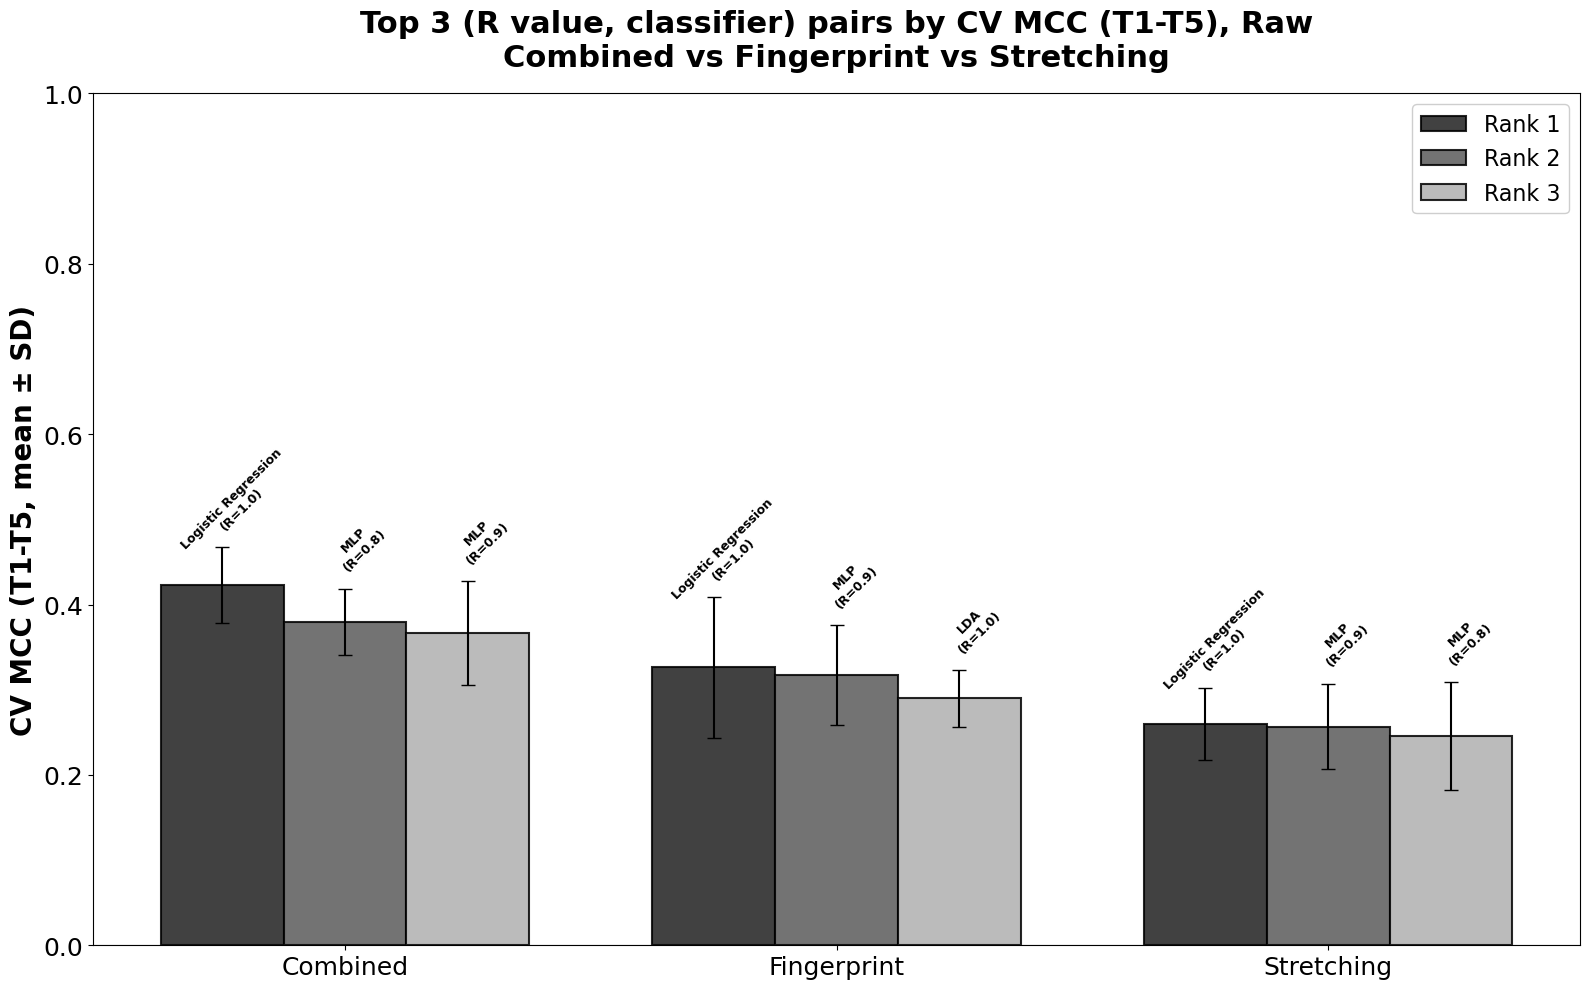

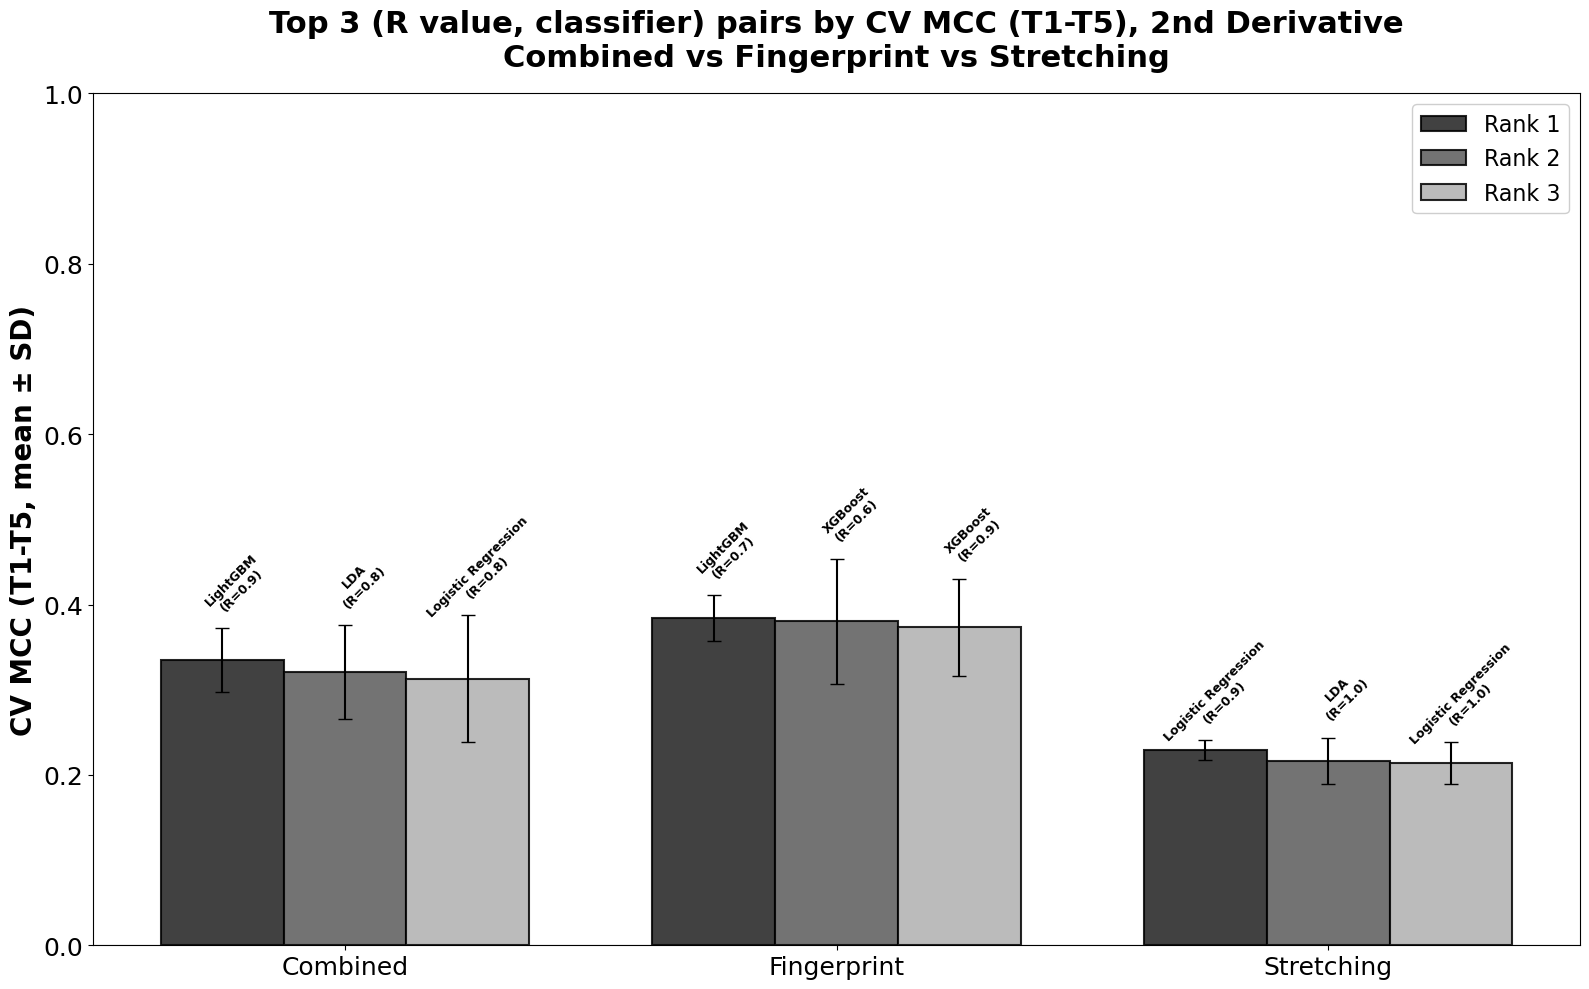

CPU times: total: 1.58 s
Wall time: 1.61 s


In [12]:
%%time
def collect_rank_values(region_top3, region_names, rank):
    means, stds, labels = [], [], []
    for region_name in region_names:
        top3 = region_top3[region_name]
        if rank < len(top3):
            row = top3.iloc[rank]
            means.append(row['Mean_CV_MCC_Pooled_T1T5'])
            stds.append(row['Std_CV_MCC_Pooled_T1T5'])
            labels.append(f"{row['Model']}\n(R={row['R_value']})")
        else:
            means.append(0.0)
            stds.append(0.0)
            labels.append('')
    return means, stds, labels


def plot_region_top3_cv_comparison(region_top3, region_names, spectrum_type_name):
    FONT_SIZES = {'title': 22, 'axis_label': 20, 'axis_ticks': 18,
                  'bar_values': 9, 'legend': 16}

    fig, ax = plt.subplots(figsize=(16, 10))
    n_ranks = 3
    width = 0.25
    x = np.arange(len(region_names))
    colors = ['#1f1f1f', '#5a5a5a', '#b0b0b0']

    ax.set_ylim(0, 1)

    for rank in range(n_ranks):
        means, stds, labels = collect_rank_values(region_top3, region_names, rank)

        offset = (rank - (n_ranks - 1) / 2) * width
        bars = ax.bar(x + offset, means, width, yerr=stds, capsize=5,
                      error_kw={'elinewidth': 1.5, 'ecolor': 'black'},
                      label=f'Rank {rank + 1}', color=colors[rank],
                      alpha=0.85, edgecolor='black', linewidth=1.5)

        for bar, mean_val, std_val, label in zip(bars, means, stds, labels):
            if label and mean_val > 0:
                y_position = bar.get_height() + std_val + 0.04
                ax.text(bar.get_x() + bar.get_width() / 2. + 0.05, y_position, label,
                        ha='center', va='bottom',
                        fontsize=FONT_SIZES['bar_values'], fontweight='bold',
                        rotation=45, rotation_mode='anchor')

    ax.set_xticks(x)
    ax.set_xticklabels(region_names, fontsize=FONT_SIZES['axis_ticks'])
    ax.set_ylabel('CV MCC (T1-T5, mean ± SD)', fontsize=FONT_SIZES['axis_label'], fontweight='bold')
    ax.set_title(f'Top 3 (R value, classifier) pairs by CV MCC (T1-T5), {spectrum_type_name}\n'
                 'Combined vs Fingerprint vs Stretching',
                 fontsize=FONT_SIZES['title'], fontweight='bold', pad=20)
    ax.tick_params(axis='y', labelsize=FONT_SIZES['axis_ticks'])
    ax.axhline(0, color='grey', linewidth=0.8)
    ax.legend(fontsize=FONT_SIZES['legend'], loc='upper right', framealpha=0.95)

    plt.tight_layout()
    spectrum_tag = spectrum_type_name.replace(' ', '')
    plt.savefig(os.path.join(OUTPUT_DIR, f'Region_Comparison_Top3_CV_MCC_T1T5_{spectrum_tag}.png'), dpi=150)
    plt.show()


for spectrum_type_name in spectrum_type_names:
    plot_region_top3_cv_comparison(region_top3_by_type[spectrum_type_name], region_names, spectrum_type_name)

## Raw vs second derivative

One figure with both spectrum types. Within each region, the top 3 for raw sit next to the top 3 for the second derivative. Shade shows rank, dark to light, and hatching shows spectrum type: solid for raw, hatched for second derivative.

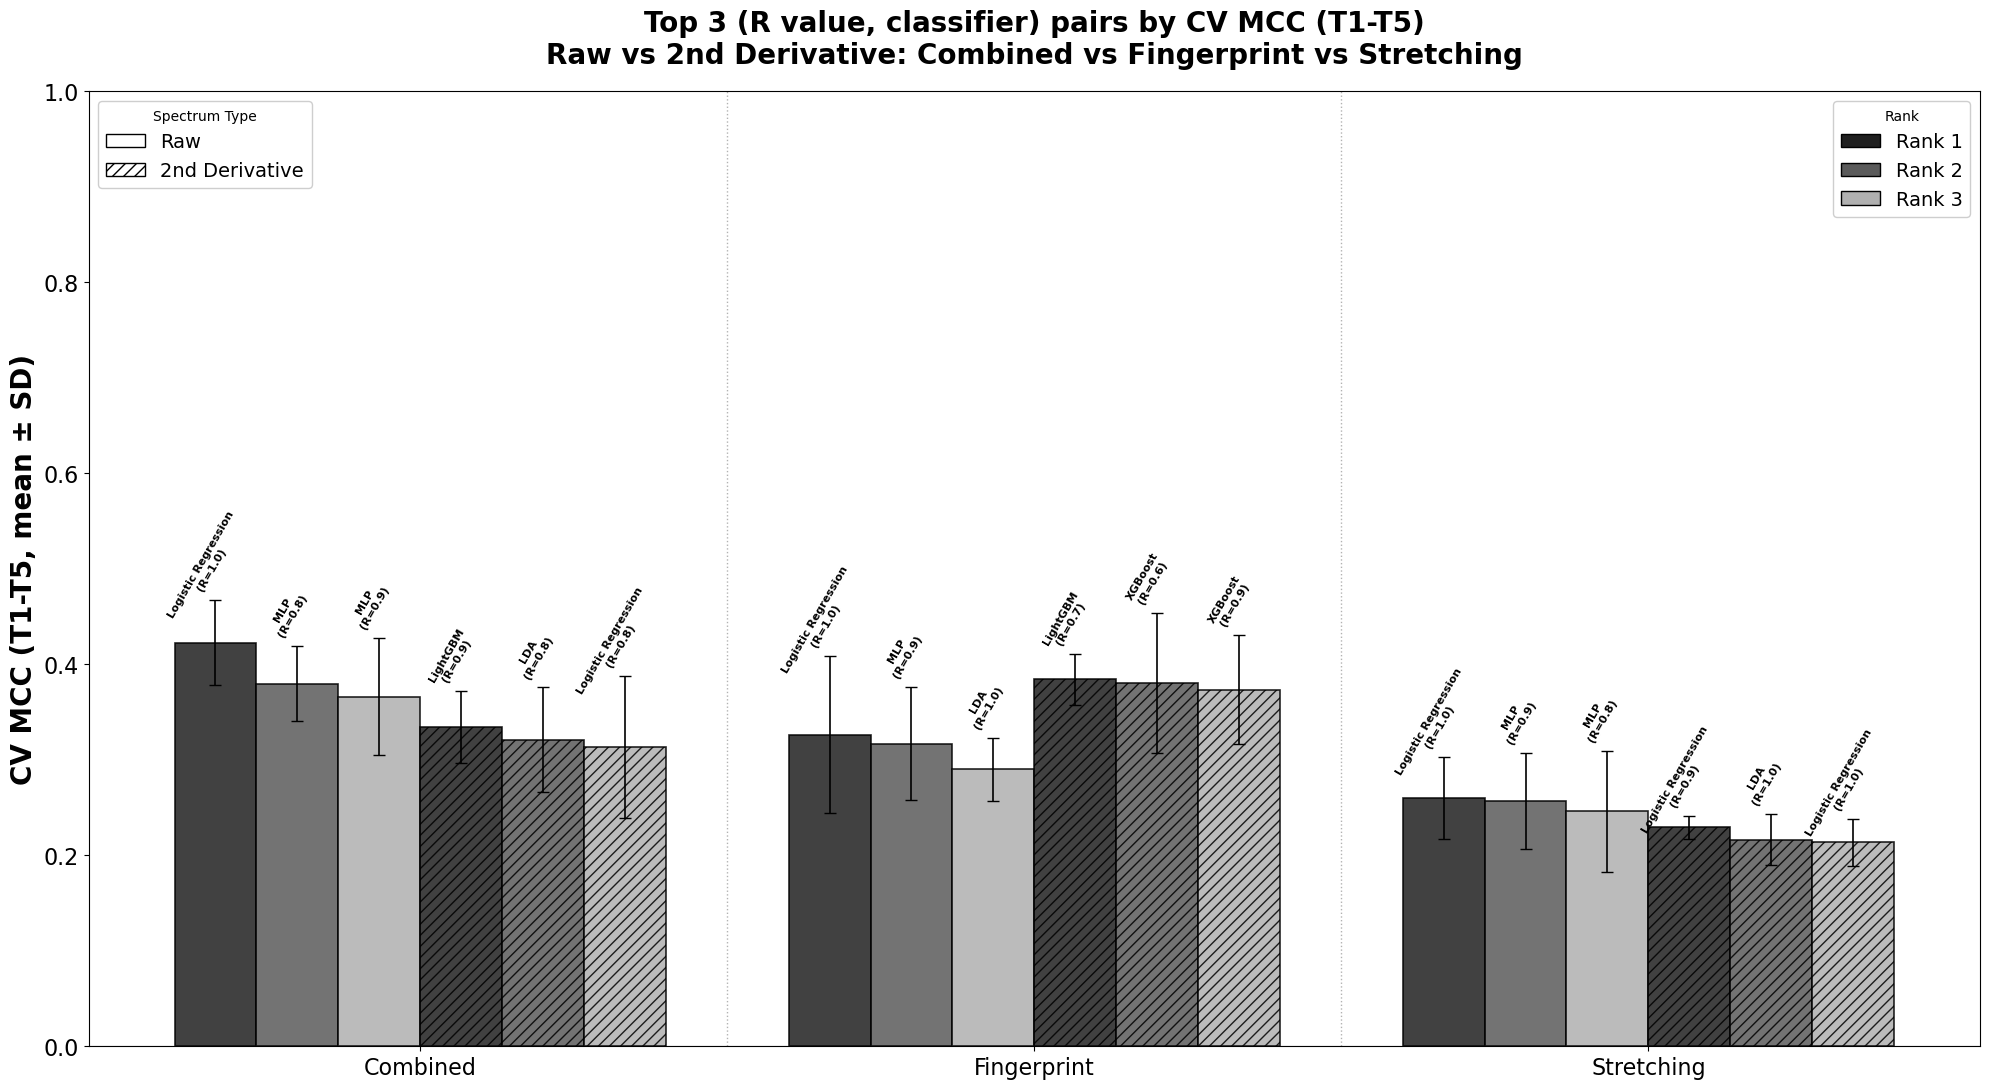

CPU times: total: 1.16 s
Wall time: 1.16 s


In [13]:
%%time
def plot_raw_vs_2ndderiv_top3_comparison(region_top3_by_type, region_names, spectrum_type_names):
    FONT_SIZES = {'title': 20, 'axis_label': 20, 'axis_ticks': 16,
                  'bar_values': 8, 'legend': 14}

    fig, ax = plt.subplots(figsize=(20, 11))
    n_ranks = 3
    n_types = len(spectrum_type_names)
    rank_colors = ['#1f1f1f', '#5a5a5a', '#b0b0b0']
    hatches = ['', '///']

    group_width = 0.8
    bar_width = group_width / (n_ranks * n_types)
    x = np.arange(len(region_names))

    ax.set_ylim(0, 1)

    slot = 0
    for type_idx, spectrum_type_name in enumerate(spectrum_type_names):
        region_top3 = region_top3_by_type[spectrum_type_name]
        for rank in range(n_ranks):
            means, stds, labels = collect_rank_values(region_top3, region_names, rank)

            offset = (slot - (n_ranks * n_types - 1) / 2) * bar_width
            bars = ax.bar(x + offset, means, bar_width, yerr=stds, capsize=4,
                          error_kw={'elinewidth': 1.2, 'ecolor': 'black'},
                          label=f'{spectrum_type_name}, rank {rank + 1}',
                          color=rank_colors[rank], hatch=hatches[type_idx],
                          alpha=0.85, edgecolor='black', linewidth=1.2)

            for bar, mean_val, std_val, label in zip(bars, means, stds, labels):
                if label and mean_val > 0:
                    y_position = bar.get_height() + std_val + 0.03
                    ax.text(bar.get_x() + bar.get_width() / 2., y_position, label,
                            ha='center', va='bottom',
                            fontsize=FONT_SIZES['bar_values'], fontweight='bold',
                            rotation=60, rotation_mode='anchor')
            slot += 1

    for region_idx in range(len(region_names) - 1):
        divider_x = (x[region_idx] + x[region_idx + 1]) / 2
        ax.axvline(x=divider_x, color='grey', linestyle=':', alpha=0.6, linewidth=1)

    ax.set_xticks(x)
    ax.set_xticklabels(region_names, fontsize=FONT_SIZES['axis_ticks'])
    ax.set_ylabel('CV MCC (T1-T5, mean ± SD)', fontsize=FONT_SIZES['axis_label'], fontweight='bold')
    ax.set_title('Top 3 (R value, classifier) pairs by CV MCC (T1-T5)\n'
                 'Raw vs 2nd Derivative: Combined vs Fingerprint vs Stretching',
                 fontsize=FONT_SIZES['title'], fontweight='bold', pad=20)
    ax.tick_params(axis='y', labelsize=FONT_SIZES['axis_ticks'])
    ax.axhline(0, color='grey', linewidth=0.8)

    rank_legend_handles = [Patch(facecolor=rank_colors[r], edgecolor='black', label=f'Rank {r + 1}')
                           for r in range(n_ranks)]
    type_legend_handles = [Patch(facecolor='white', edgecolor='black', hatch=hatches[t],
                                 label=spectrum_type_names[t]) for t in range(n_types)]
    rank_legend = ax.legend(handles=rank_legend_handles, fontsize=FONT_SIZES['legend'],
                            loc='upper right', framealpha=0.95, title='Rank')
    ax.add_artist(rank_legend)
    ax.legend(handles=type_legend_handles, fontsize=FONT_SIZES['legend'],
              loc='upper left', framealpha=0.95, title='Spectrum Type')

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'Region_Comparison_Top3_CV_MCC_T1T5_Raw_vs_2ndDerivative.png'), dpi=150)
    plt.show()


plot_raw_vs_2ndderiv_top3_comparison(region_top3_by_type, region_names, spectrum_type_names)

## Top 3 candidates: CV MCC vs test MCC

For each spectrum type, region and top-3 candidate, a per-timepoint profile (T0–T7) with the out-of-fold CV MCC and the test MCC, titled with the pooled T1–T5 CV MCC. Each profile is saved as a grouped bar chart marked with the pre-infection, asymptomatic and symptomatic phases, and as rows in the profile CSV files.


[Raw | Combined] Candidate #1: Logistic Regression (R=1.0), CV MCC (T1-T5) = 0.423 ± 0.044
Timepoint Display_Timepoint   CV_MCC  CV_MCC_Std  Test_MCC
       T0              0dpi      NaN         NaN  0.094157
       T1              3dpi 0.390622    0.097399  0.131991
       T2              7dpi 0.383966    0.099680  0.401498
       T3             10dpi 0.572947    0.114194  0.451292
       T4             14dpi 0.373361    0.075512  0.368932
       T5             17dpi 0.389056    0.125666  0.345106
       T6             21dpi      NaN         NaN  0.376490
       T7             24dpi      NaN         NaN  0.276746


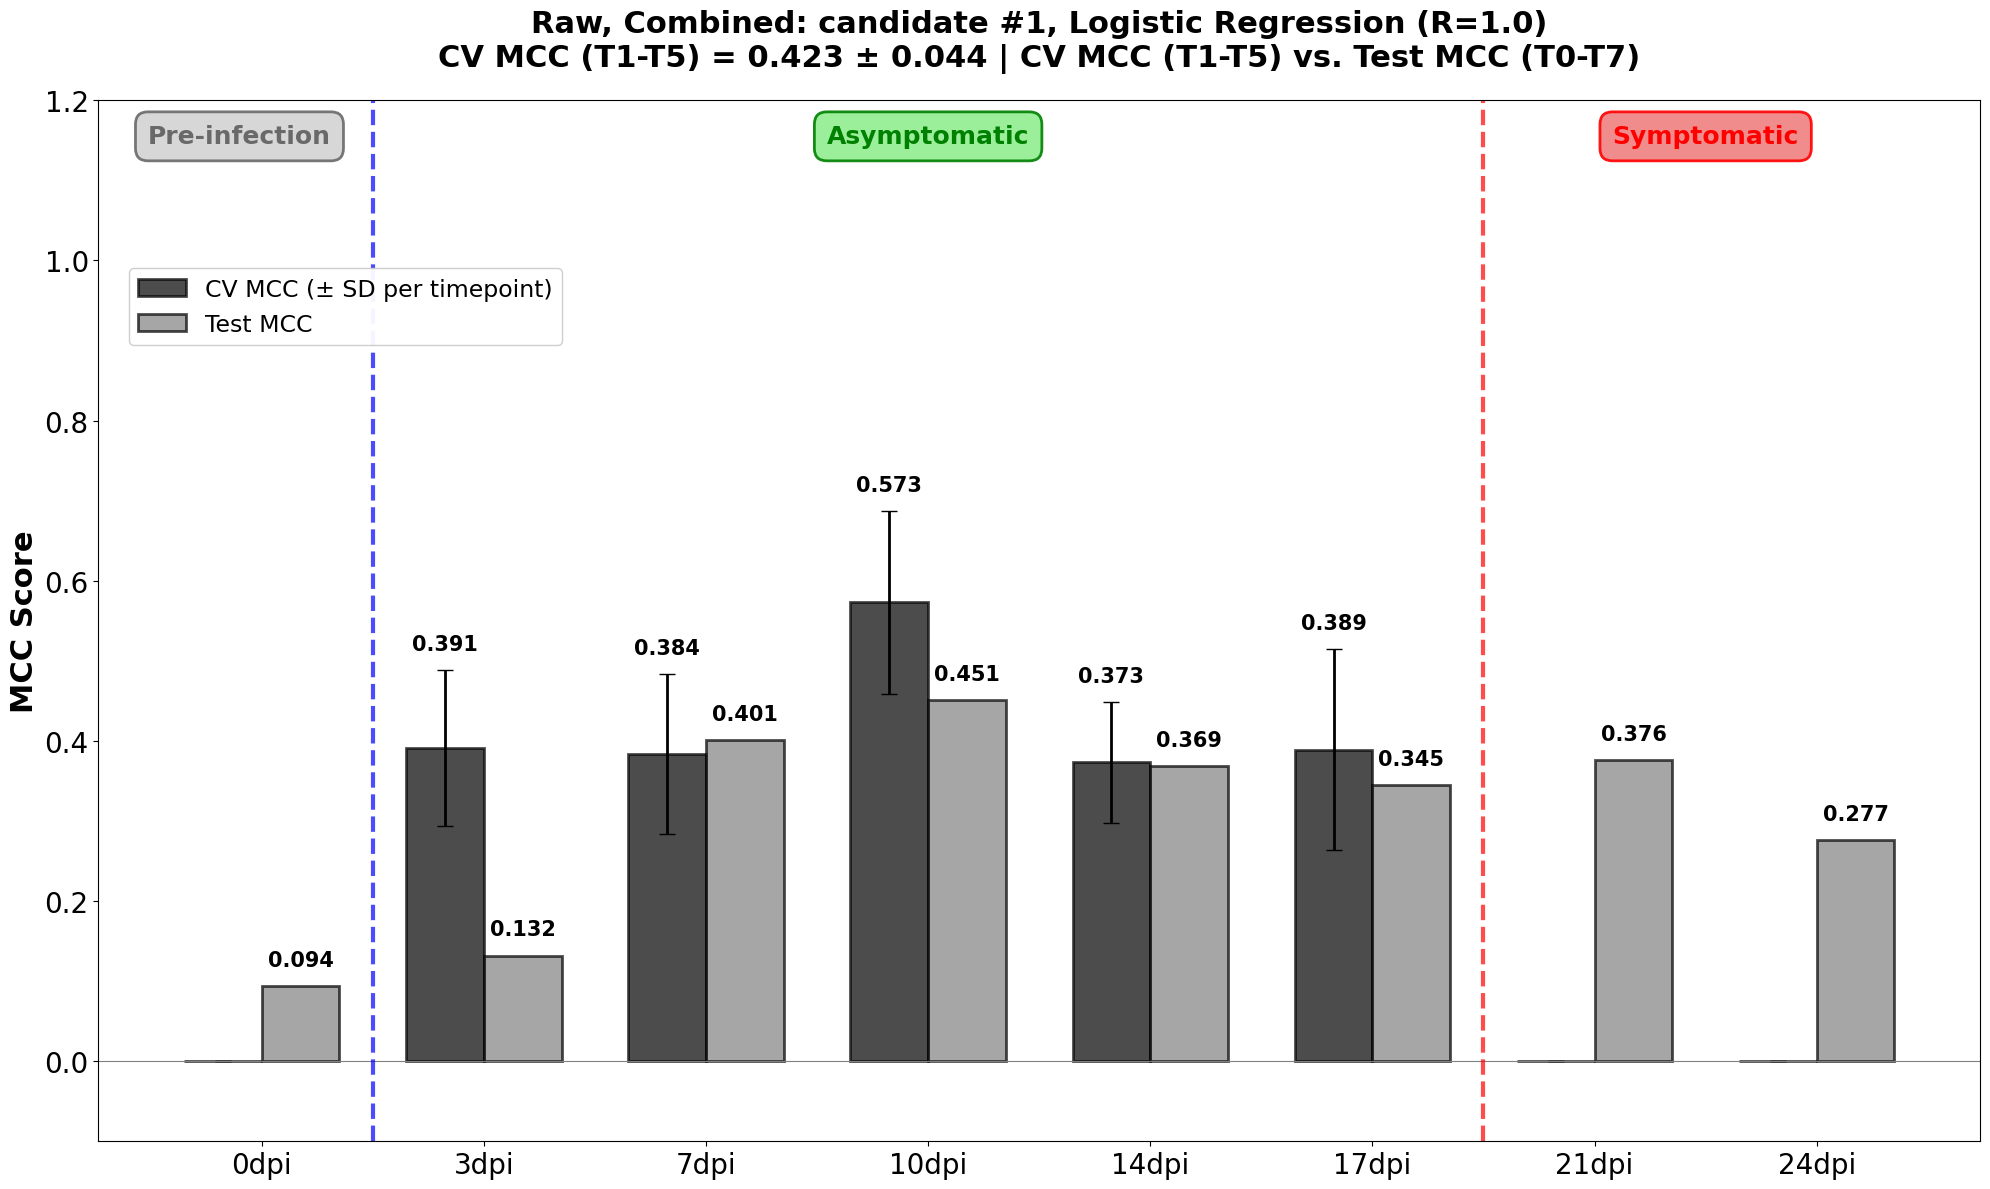


[Raw | Combined] Candidate #2: MLP (R=0.8), CV MCC (T1-T5) = 0.379 ± 0.039
Timepoint Display_Timepoint   CV_MCC  CV_MCC_Std  Test_MCC
       T0              0dpi      NaN         NaN  0.062283
       T1              3dpi 0.342592    0.127231  0.345106
       T2              7dpi 0.341374    0.122837  0.339533
       T3             10dpi 0.438932    0.078953  0.447523
       T4             14dpi 0.432834    0.038166  0.052926
       T5             17dpi 0.343865    0.136956  0.289574
       T6             21dpi      NaN         NaN  0.353866
       T7             24dpi      NaN         NaN  0.250281


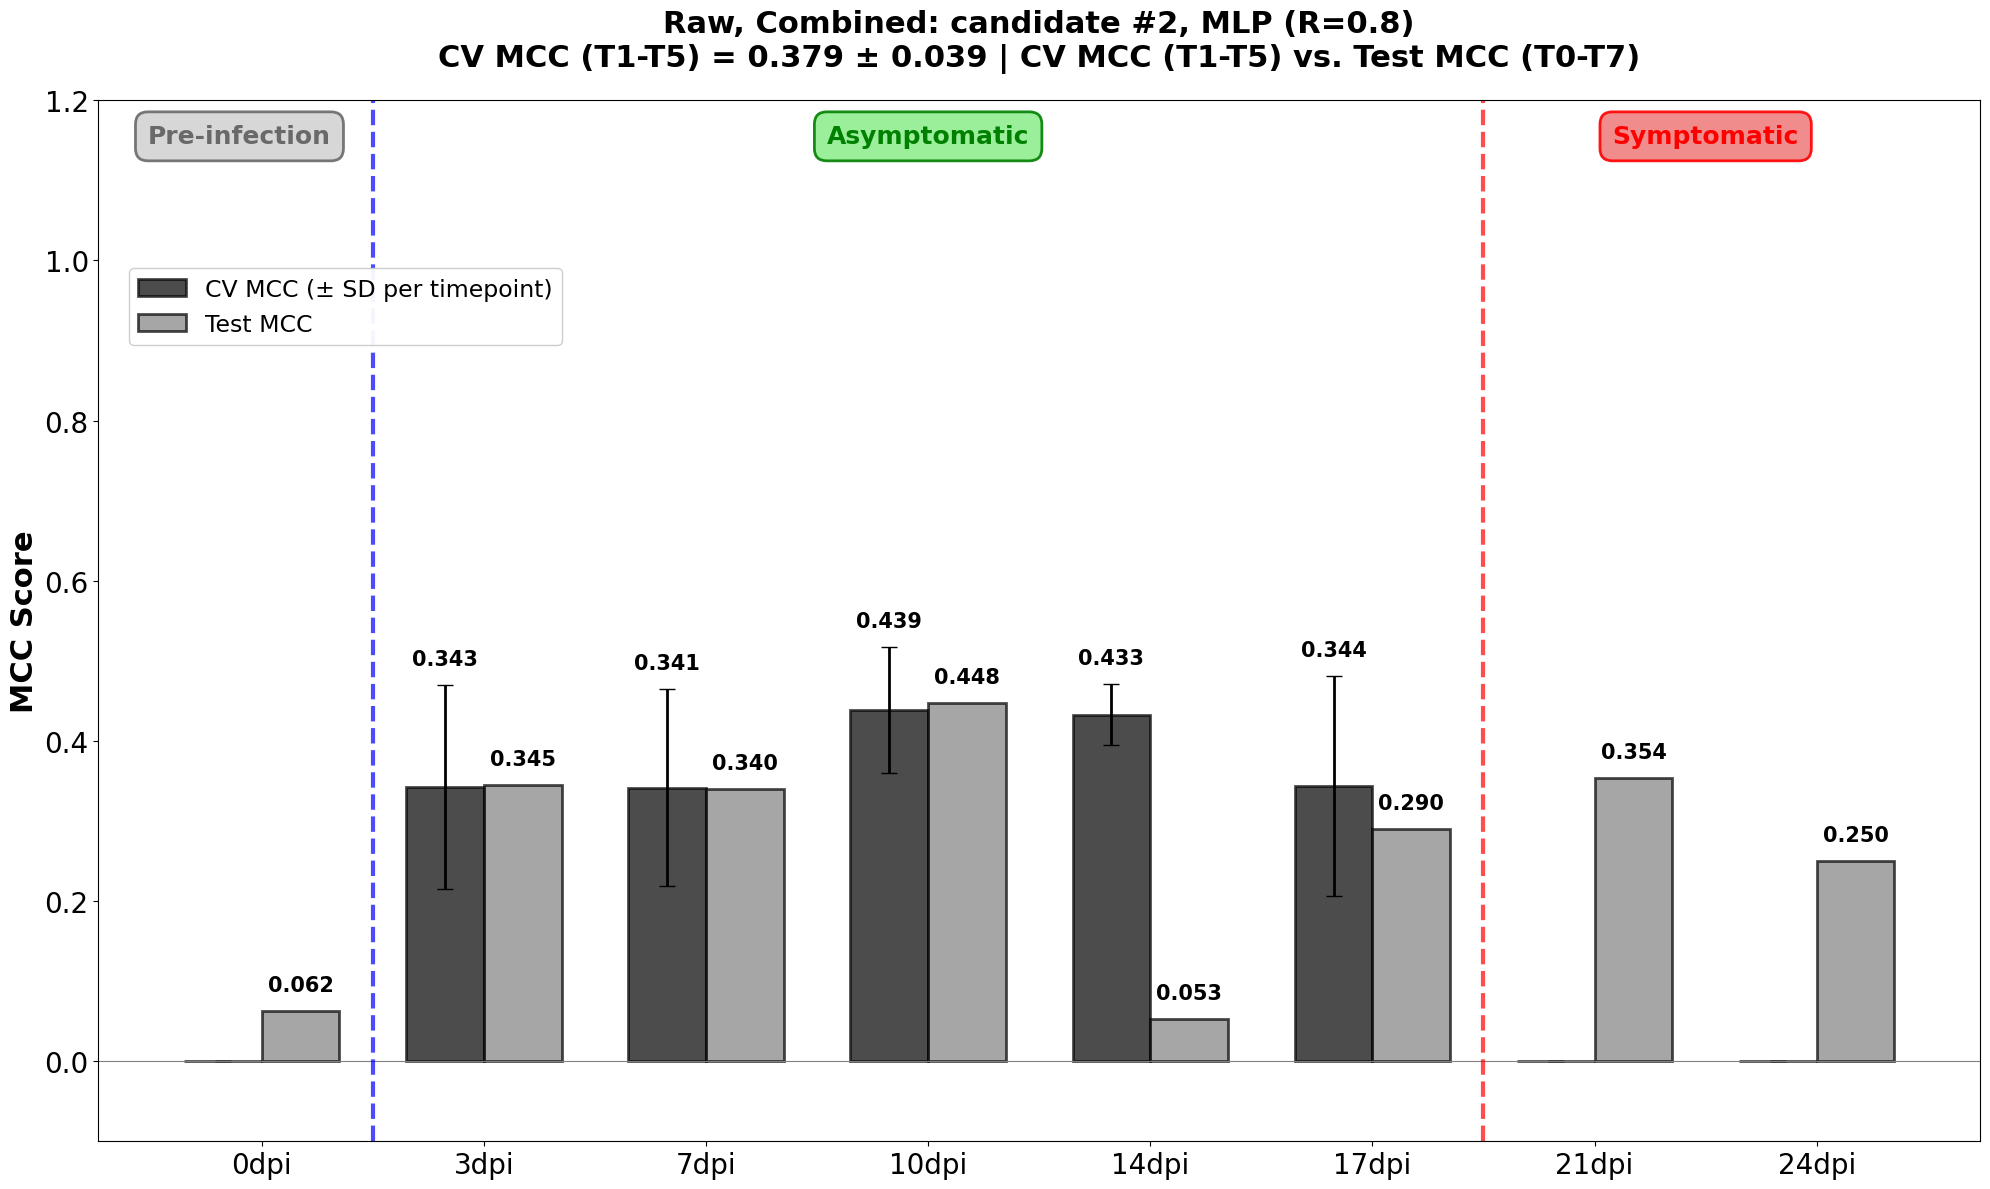


[Raw | Combined] Candidate #3: MLP (R=0.9), CV MCC (T1-T5) = 0.366 ± 0.061
Timepoint Display_Timepoint   CV_MCC  CV_MCC_Std  Test_MCC
       T0              0dpi      NaN         NaN  0.148989
       T1              3dpi 0.298376    0.139393  0.342224
       T2              7dpi 0.382429    0.160327  0.162616
       T3             10dpi 0.447688    0.102248  0.473684
       T4             14dpi 0.366293    0.107535  0.158777
       T5             17dpi 0.352319    0.076120  0.394874
       T6             21dpi      NaN         NaN  0.394280
       T7             24dpi      NaN         NaN  0.263524


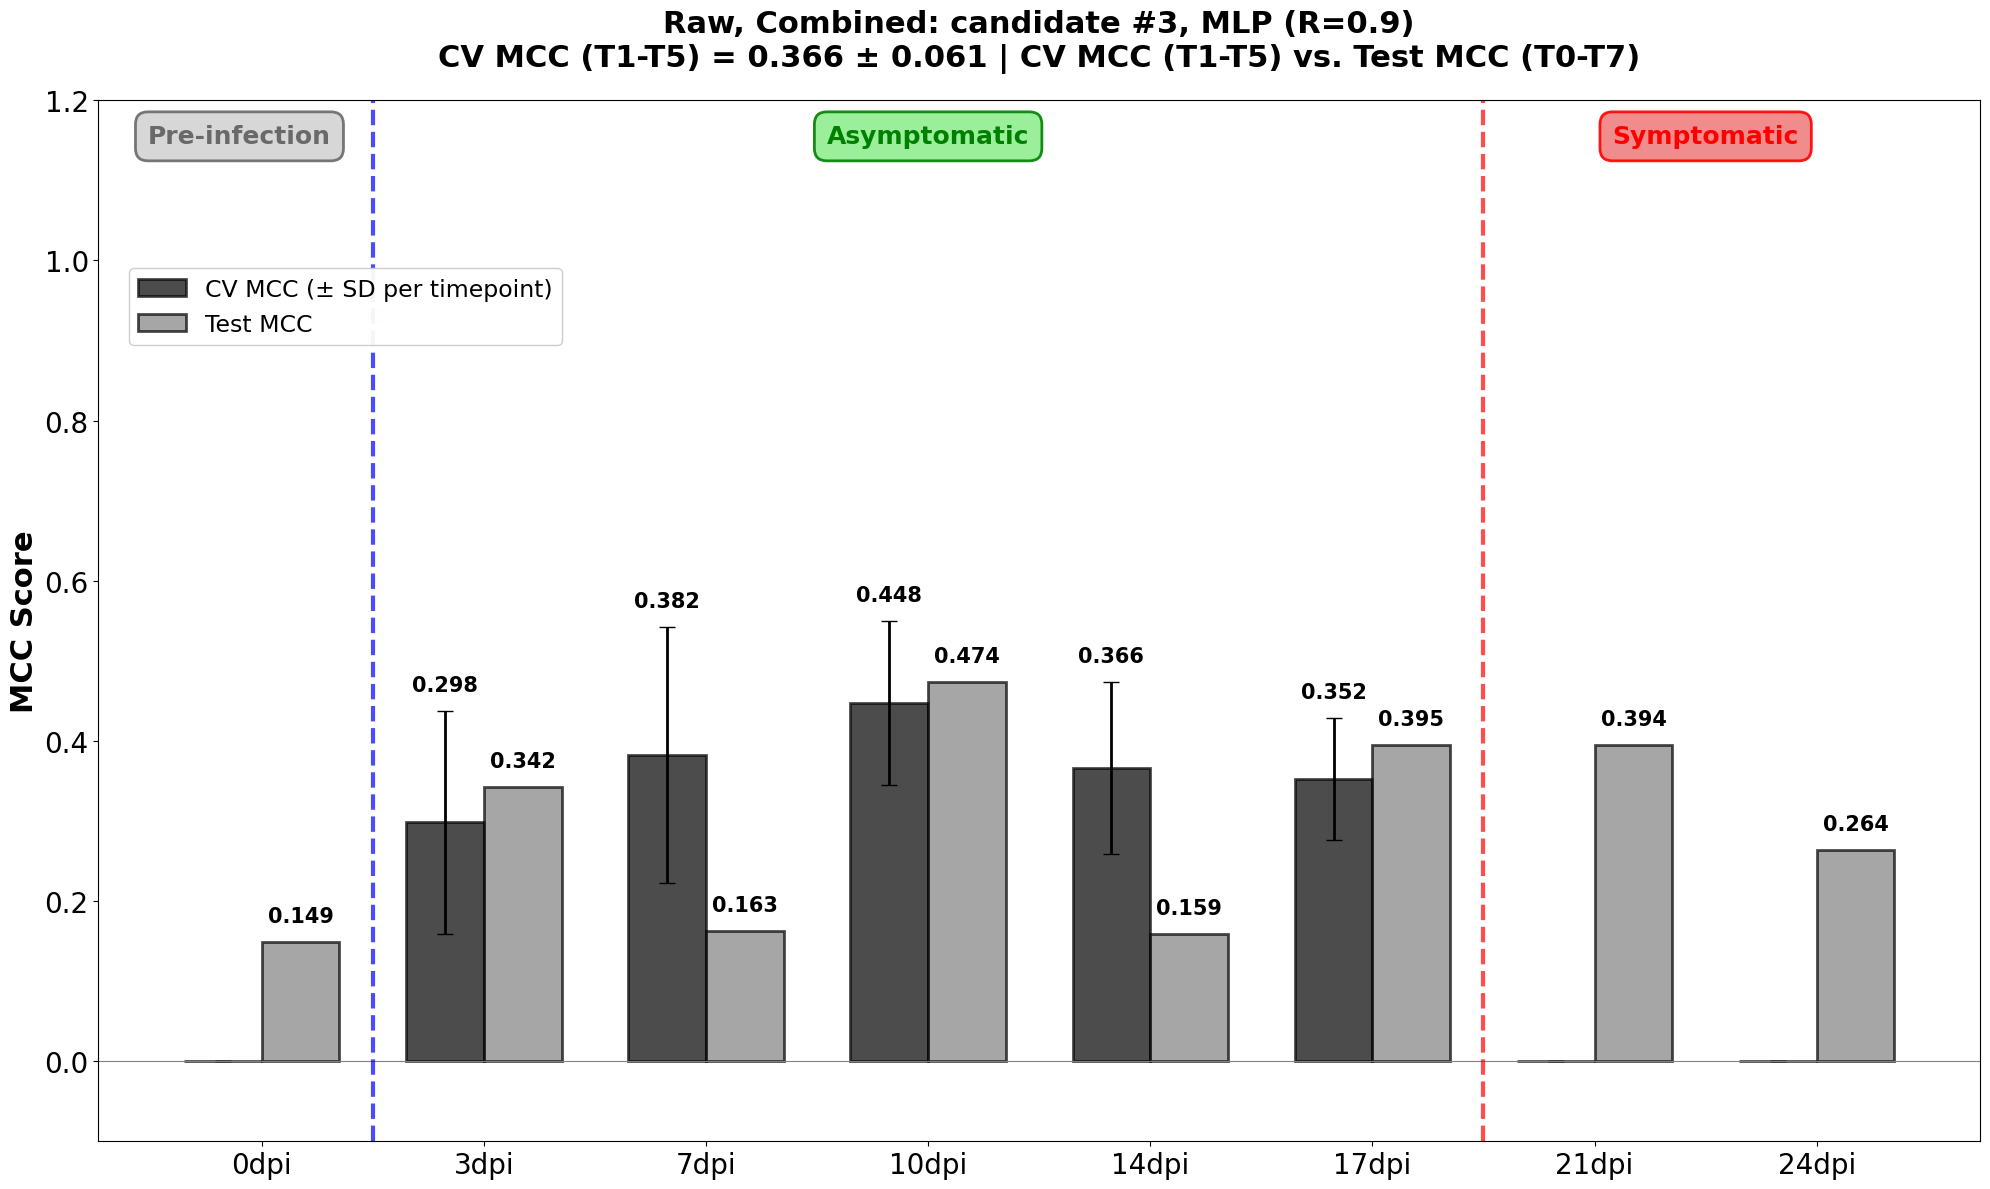


[Raw | Fingerprint] Candidate #1: Logistic Regression (R=1.0), CV MCC (T1-T5) = 0.326 ± 0.082
Timepoint Display_Timepoint   CV_MCC  CV_MCC_Std  Test_MCC
       T0              0dpi      NaN         NaN  0.029780
       T1              3dpi 0.257925    0.066941  0.056614
       T2              7dpi 0.312378    0.099304  0.233510
       T3             10dpi 0.414931    0.151368  0.504385
       T4             14dpi 0.321567    0.087578  0.289574
       T5             17dpi 0.335479    0.129493  0.368421
       T6             21dpi      NaN         NaN  0.310823
       T7             24dpi      NaN         NaN  0.240603


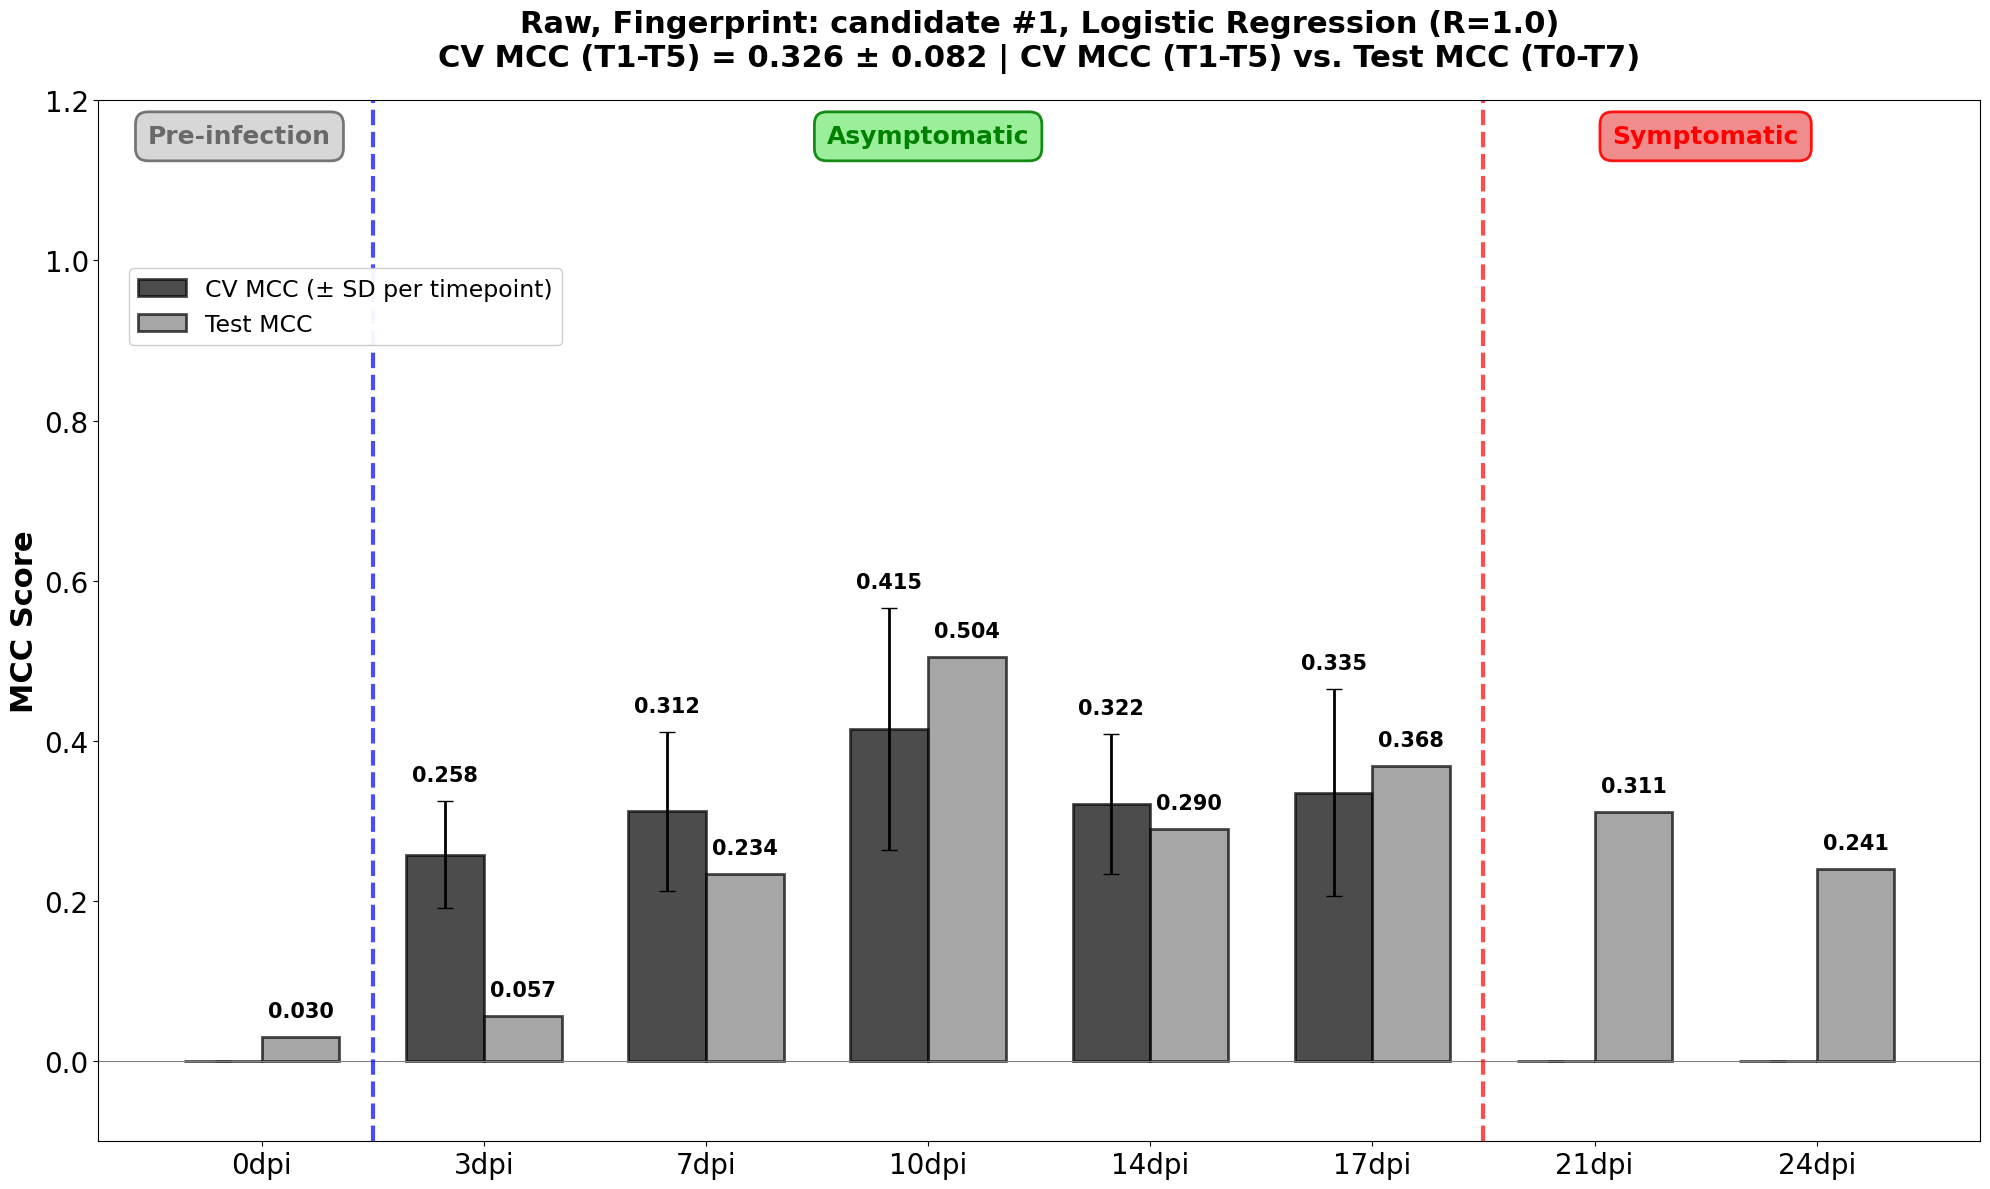


[Raw | Fingerprint] Candidate #2: MLP (R=0.9), CV MCC (T1-T5) = 0.317 ± 0.059
Timepoint Display_Timepoint   CV_MCC  CV_MCC_Std  Test_MCC
       T0              0dpi      NaN         NaN  0.143984
       T1              3dpi 0.263345    0.132333  0.107676
       T2              7dpi 0.326625    0.111864  0.105786
       T3             10dpi 0.359474    0.167013  0.290380
       T4             14dpi 0.371116    0.084939  0.316228
       T5             17dpi 0.277462    0.162644  0.368421
       T6             21dpi      NaN         NaN  0.338982
       T7             24dpi      NaN         NaN  0.236697


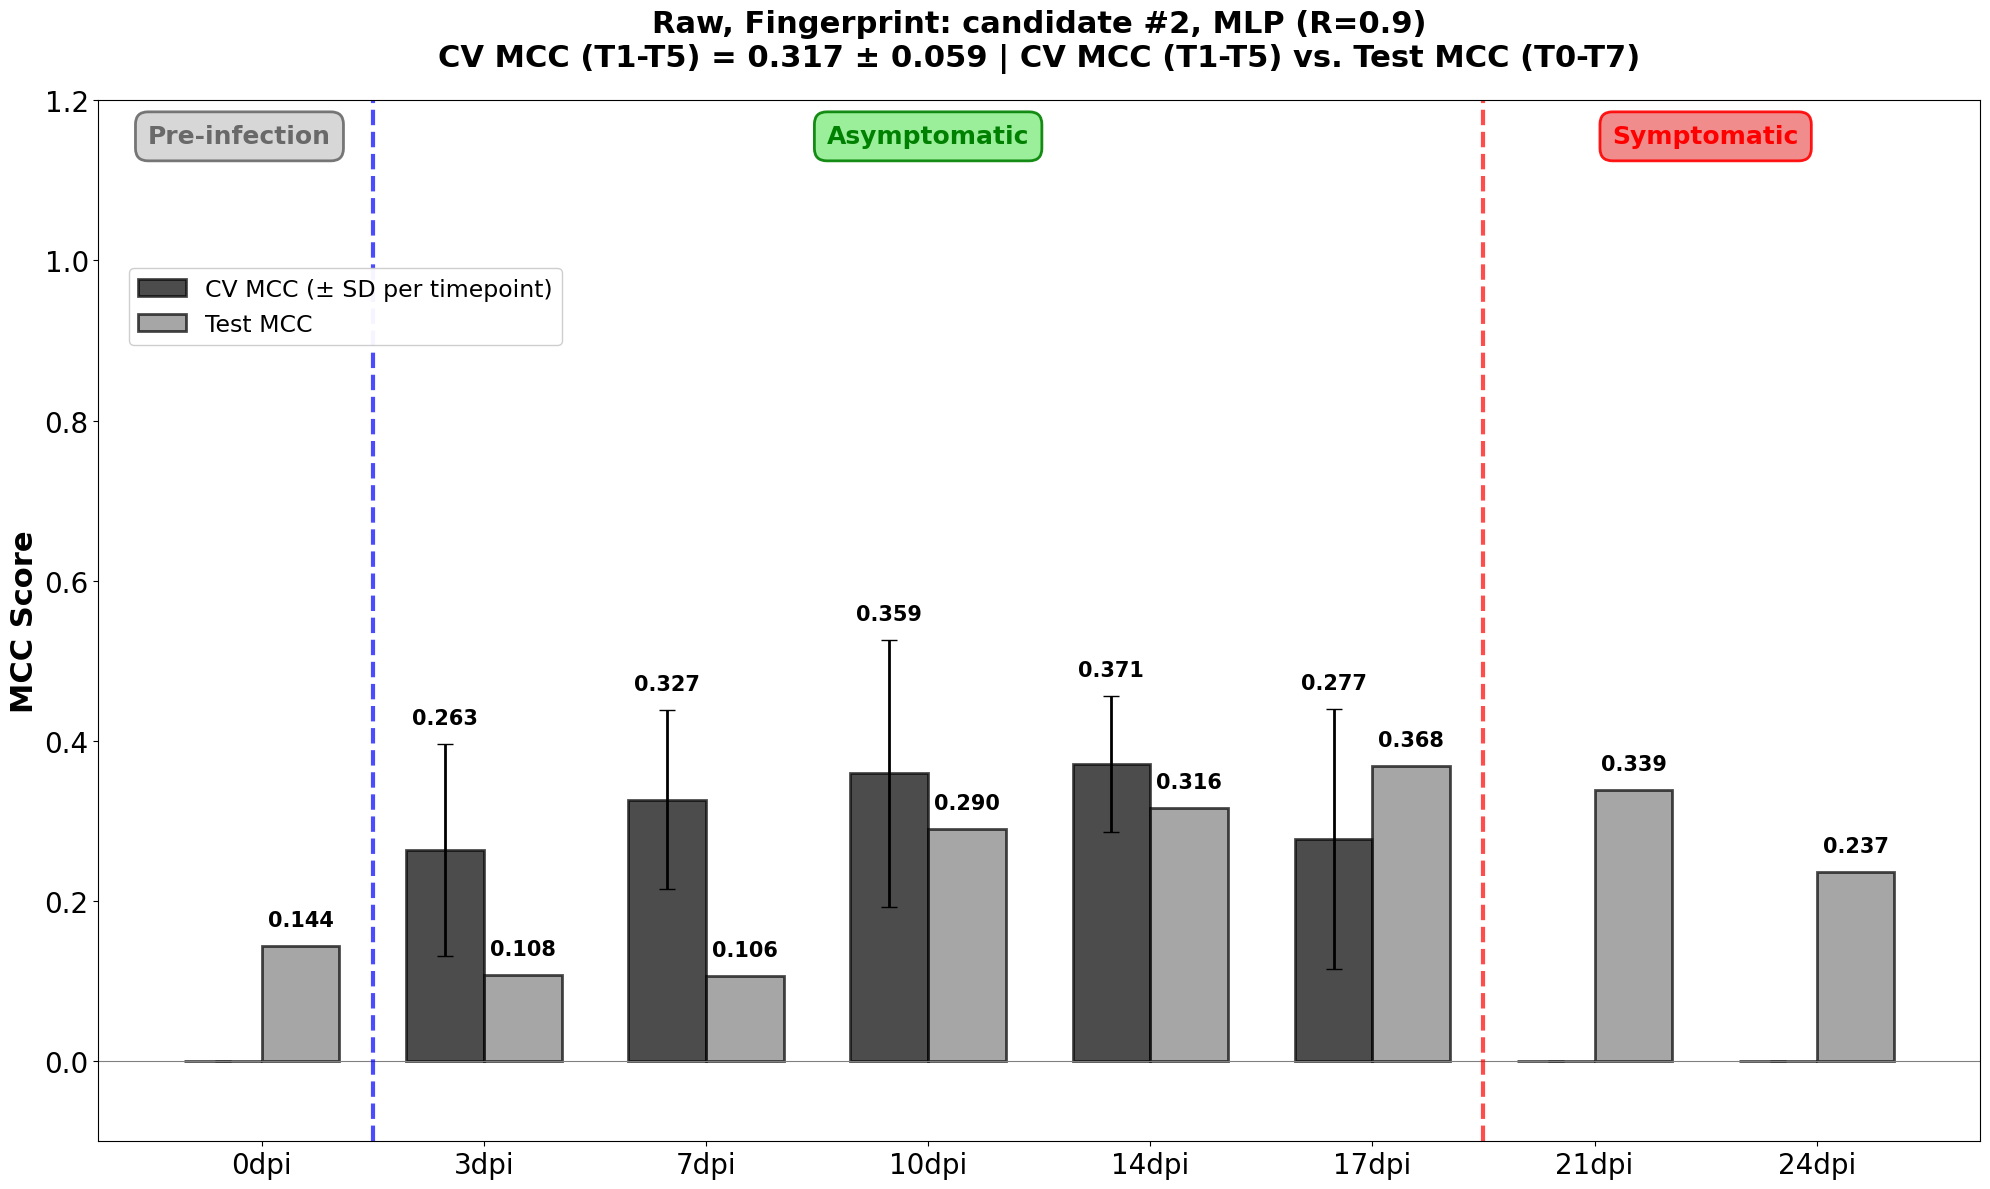


[Raw | Fingerprint] Candidate #3: LDA (R=1.0), CV MCC (T1-T5) = 0.290 ± 0.033
Timepoint Display_Timepoint   CV_MCC  CV_MCC_Std  Test_MCC
       T0              0dpi      NaN         NaN  0.036789
       T1              3dpi 0.248093    0.088303  0.132733
       T2              7dpi 0.241213    0.125863  0.243332
       T3             10dpi 0.319848    0.083074  0.236924
       T4             14dpi 0.324900    0.130337  0.131625
       T5             17dpi 0.317389    0.096085  0.316228
       T6             21dpi      NaN         NaN  0.361519
       T7             24dpi      NaN         NaN  0.209726


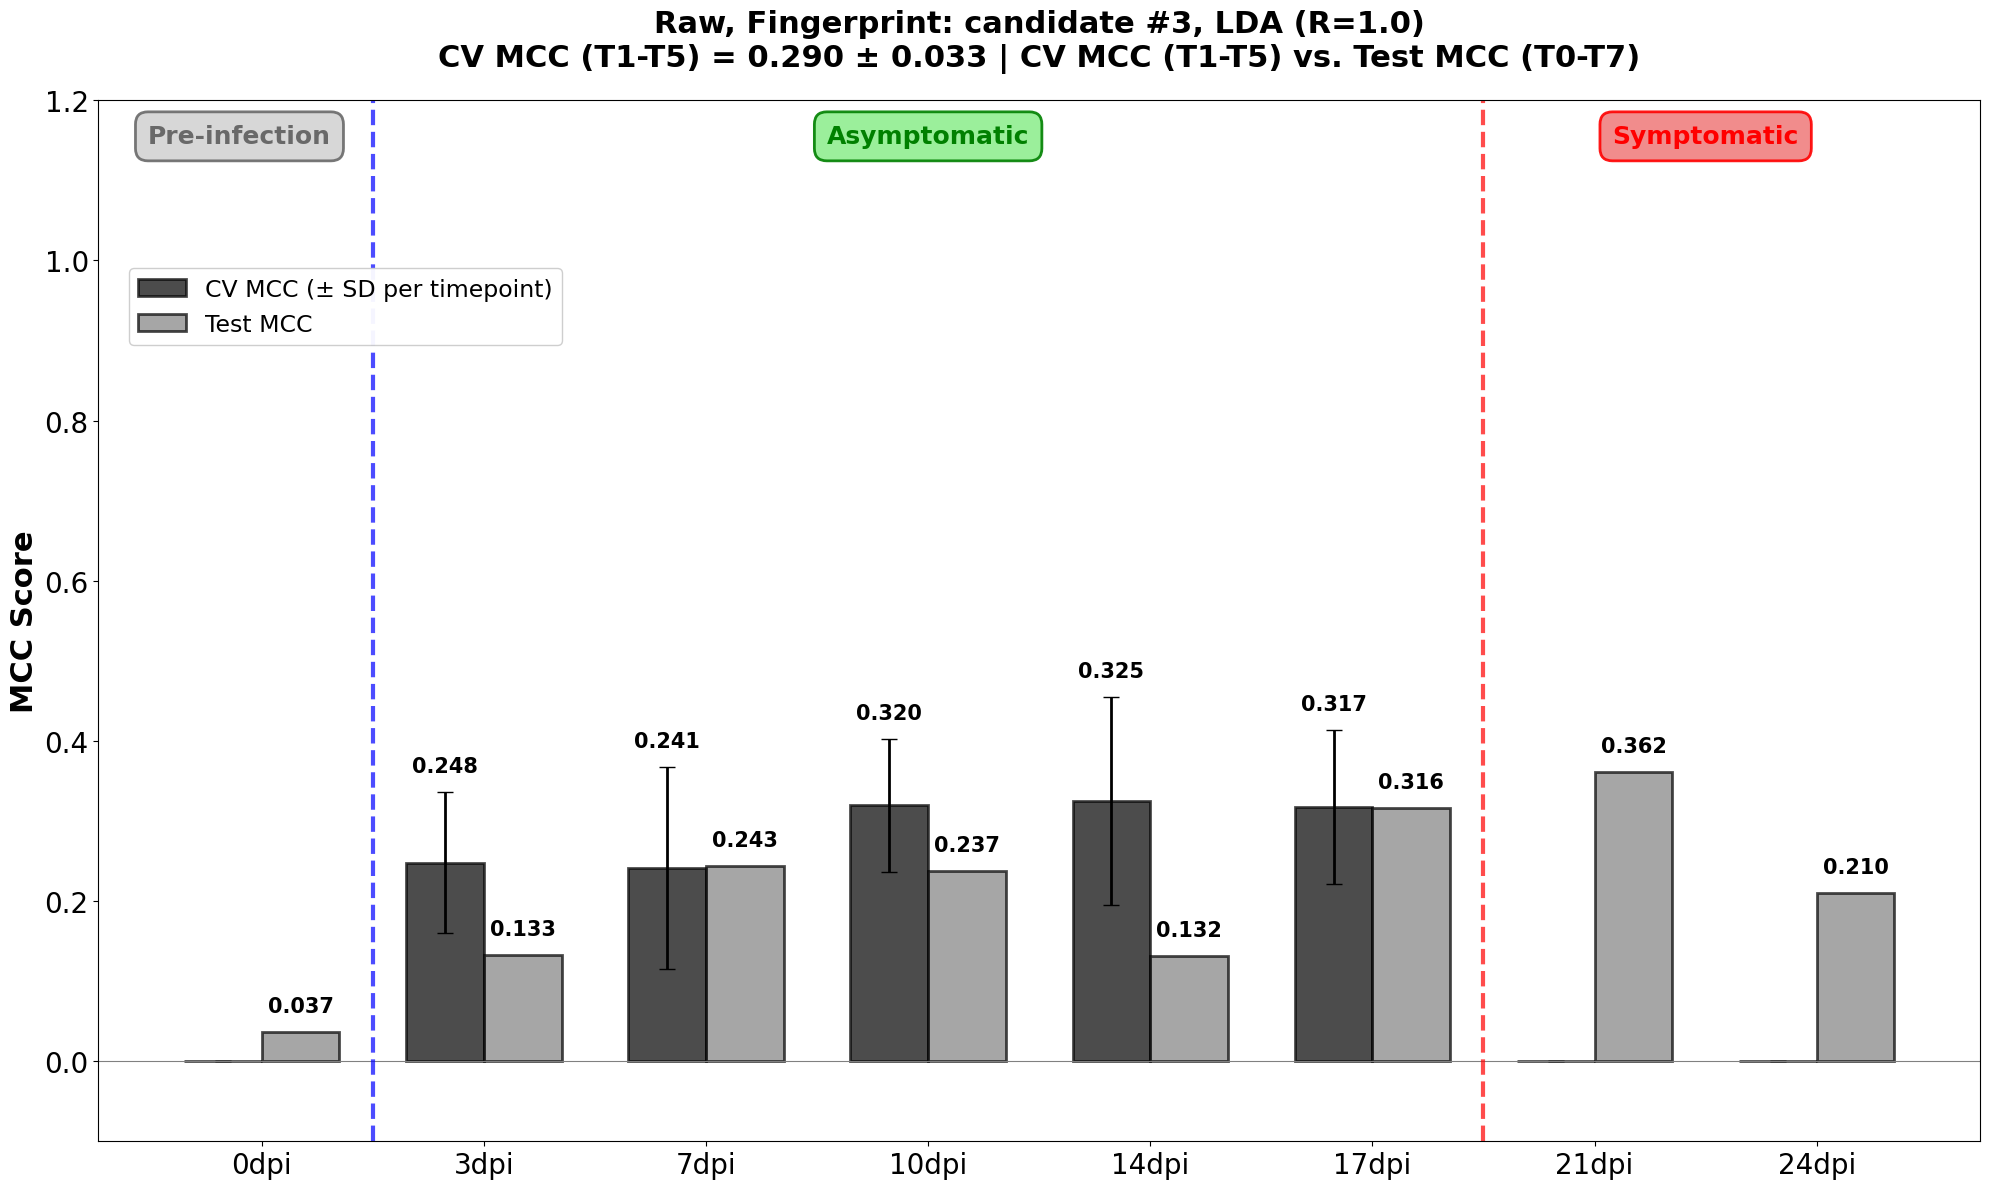


[Raw | Stretching] Candidate #1: Logistic Regression (R=1.0), CV MCC (T1-T5) = 0.260 ± 0.043
Timepoint Display_Timepoint   CV_MCC  CV_MCC_Std  Test_MCC
       T0              0dpi      NaN         NaN  0.147005
       T1              3dpi 0.214980    0.124394  0.078975
       T2              7dpi 0.226310    0.148857  0.260499
       T3             10dpi 0.342285    0.110864  0.501565
       T4             14dpi 0.262506    0.125764  0.158777
       T5             17dpi 0.262937    0.040669  0.211702
       T6             21dpi      NaN         NaN  0.262680
       T7             24dpi      NaN         NaN  0.229357


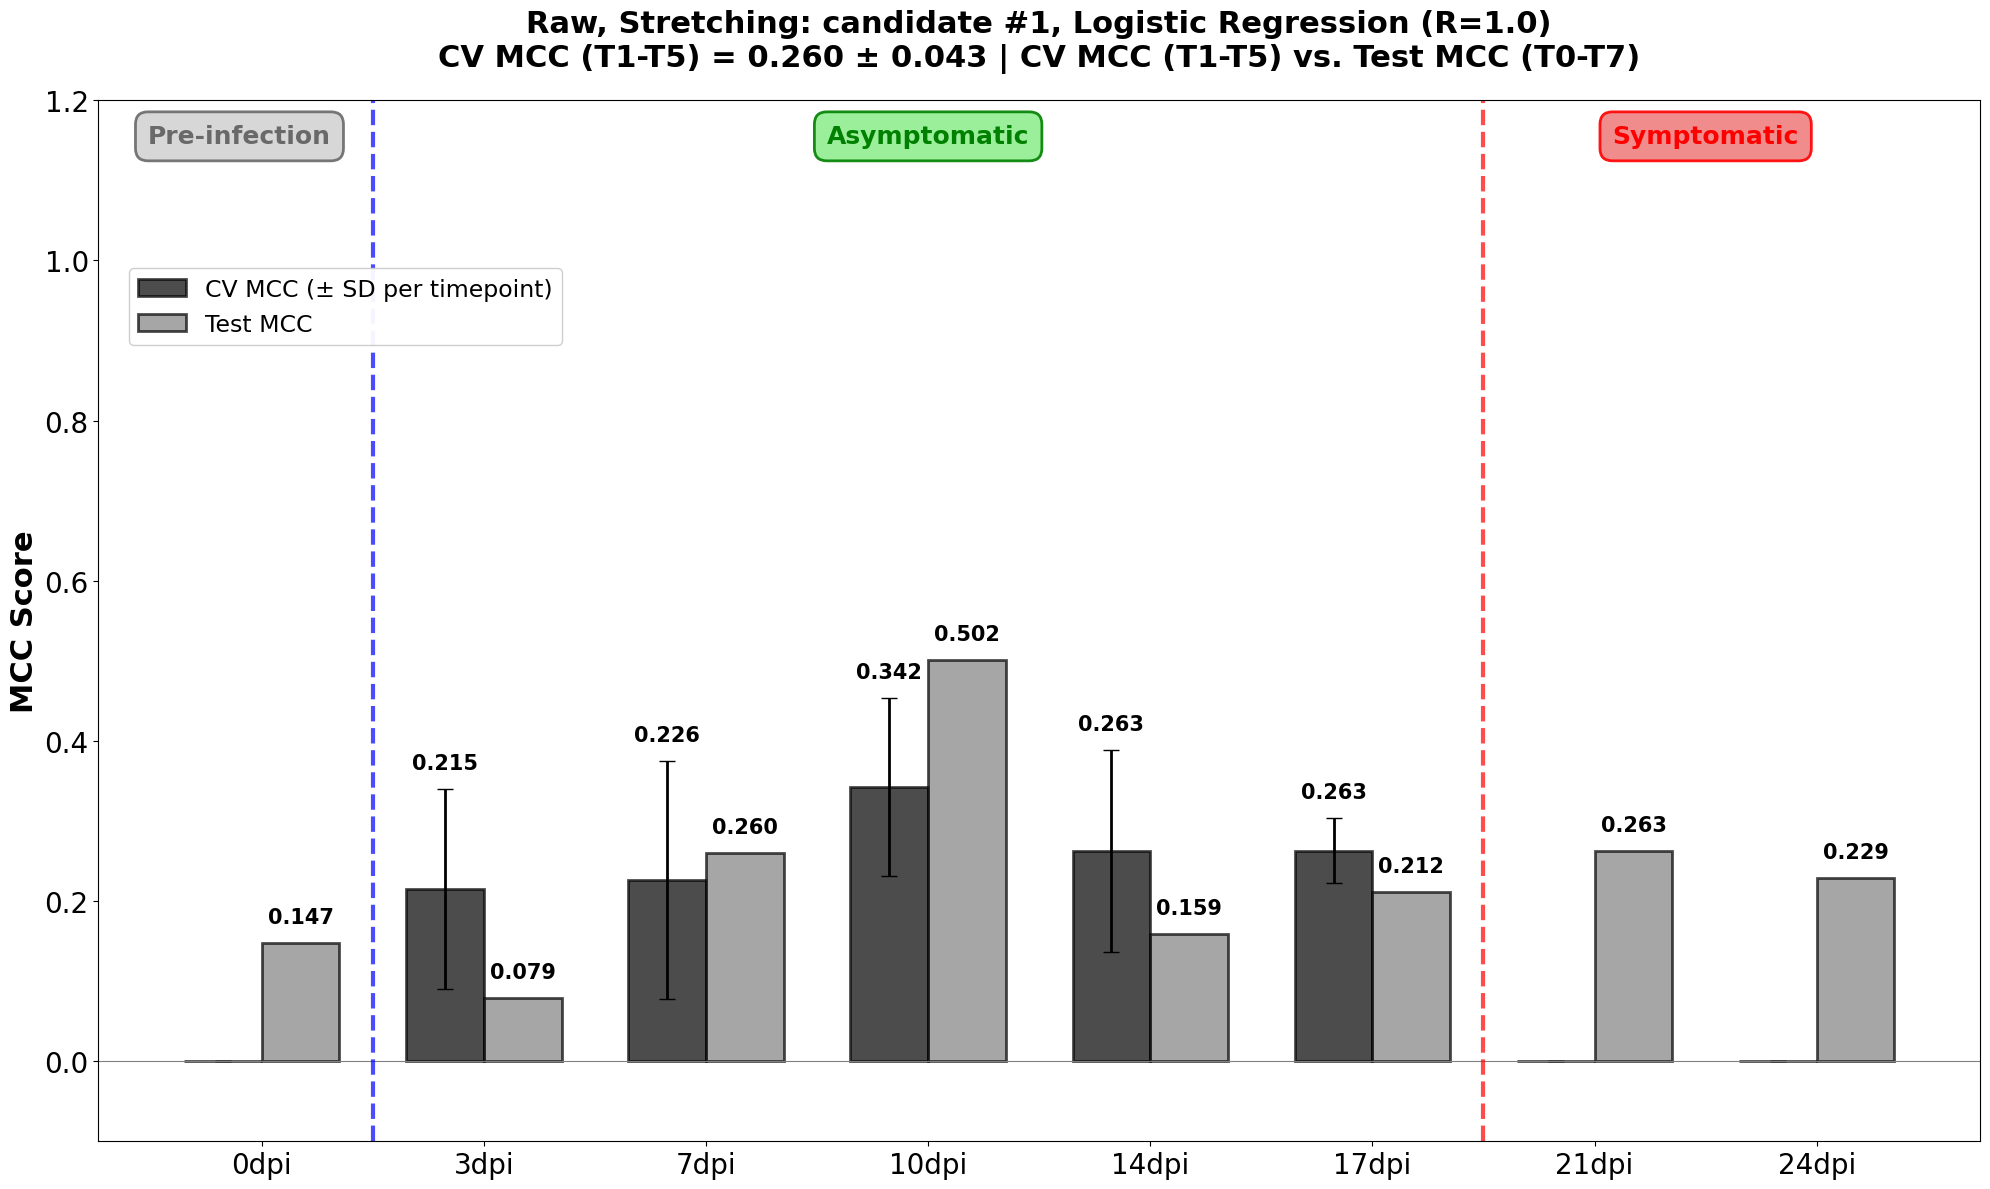


[Raw | Stretching] Candidate #2: MLP (R=0.9), CV MCC (T1-T5) = 0.257 ± 0.050
Timepoint Display_Timepoint   CV_MCC  CV_MCC_Std  Test_MCC
       T0              0dpi      NaN         NaN  0.199911
       T1              3dpi 0.250128    0.161305  0.237584
       T2              7dpi 0.122511    0.103349  0.229714
       T3             10dpi 0.303340    0.054113  0.342224
       T4             14dpi 0.289025    0.106088  0.081259
       T5             17dpi 0.323284    0.123065  0.266501
       T6             21dpi      NaN         NaN  0.304125
       T7             24dpi      NaN         NaN  0.206732


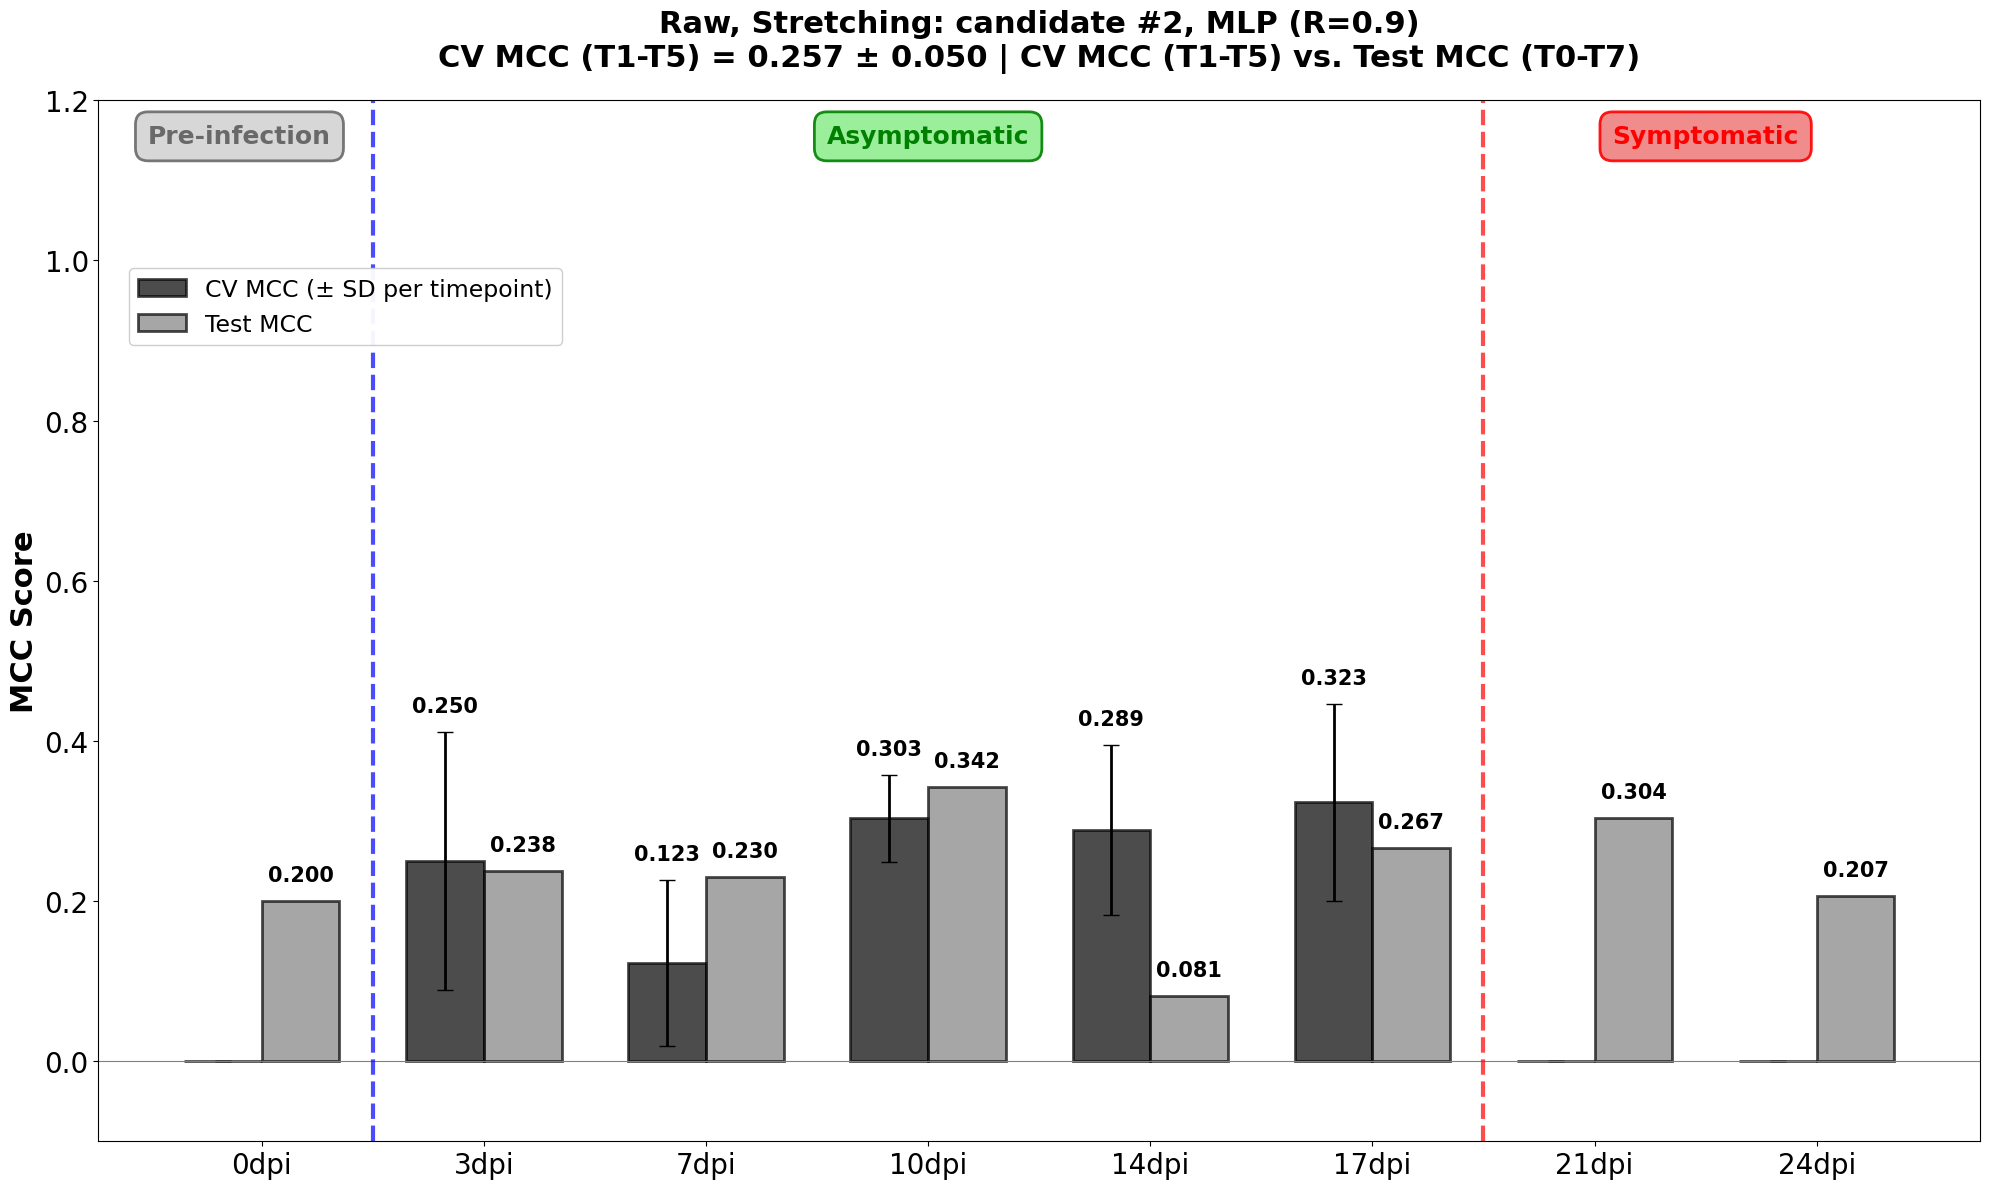


[Raw | Stretching] Candidate #3: MLP (R=0.8), CV MCC (T1-T5) = 0.246 ± 0.063
Timepoint Display_Timepoint   CV_MCC  CV_MCC_Std  Test_MCC
       T0              0dpi      NaN         NaN  0.078365
       T1              3dpi 0.262355    0.083167  0.342224
       T2              7dpi 0.086348    0.171543  0.145095
       T3             10dpi 0.295265    0.153554  0.316228
       T4             14dpi 0.258439    0.117350  0.292013
       T5             17dpi 0.331703    0.110361  0.263158
       T6             21dpi      NaN         NaN  0.343946
       T7             24dpi      NaN         NaN  0.184850


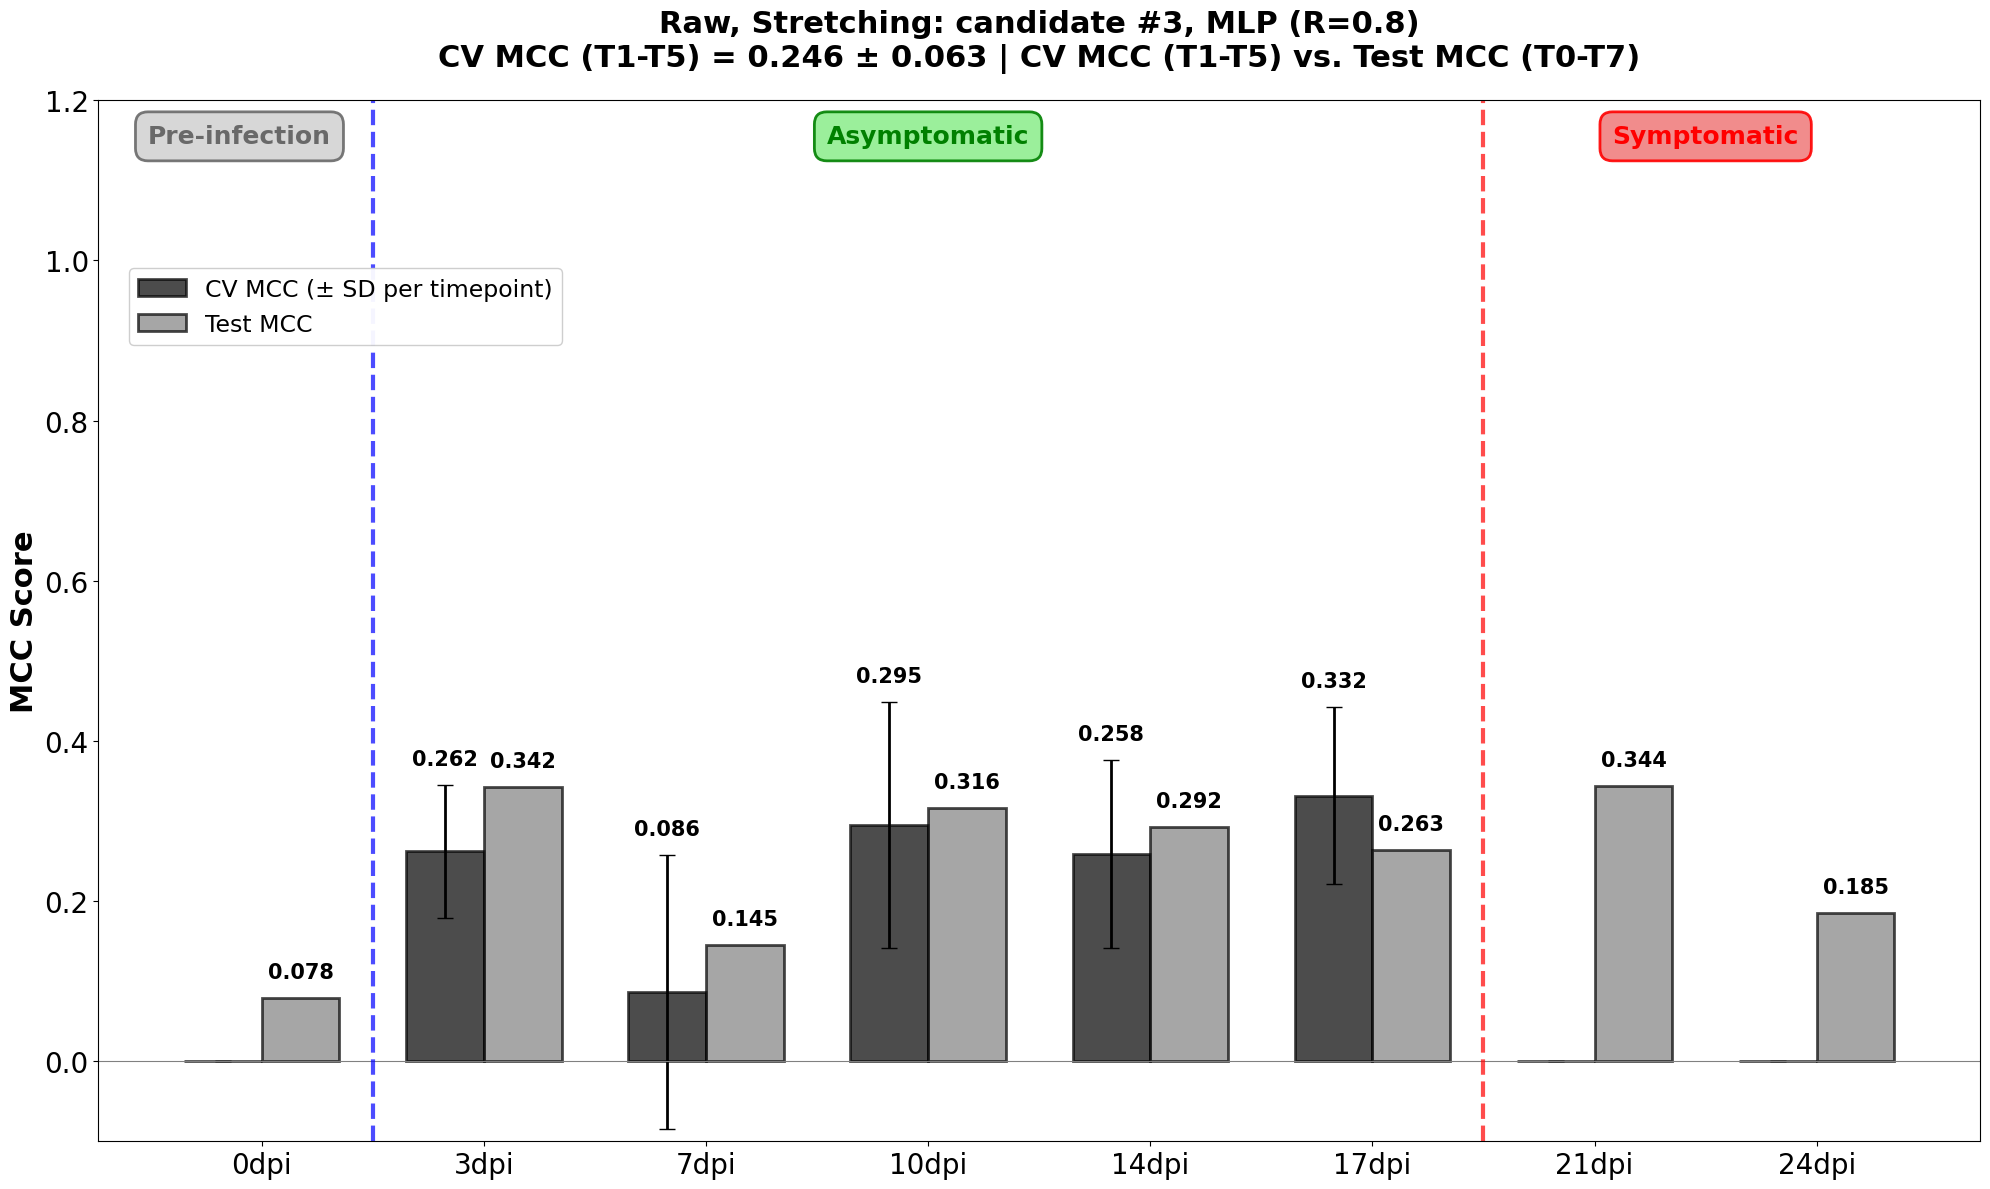


[2nd Derivative | Combined] Candidate #1: LightGBM (R=0.9), CV MCC (T1-T5) = 0.334 ± 0.038
Timepoint Display_Timepoint   CV_MCC  CV_MCC_Std  Test_MCC
       T0              0dpi      NaN         NaN  0.052153
       T1              3dpi 0.232943    0.065008 -0.026547
       T2              7dpi 0.206910    0.107984  0.236082
       T3             10dpi 0.437604    0.083723  0.423405
       T4             14dpi 0.386524    0.125773  0.460470
       T5             17dpi 0.420823    0.097628  0.317554
       T6             21dpi      NaN         NaN  0.359833
       T7             24dpi      NaN         NaN  0.356620


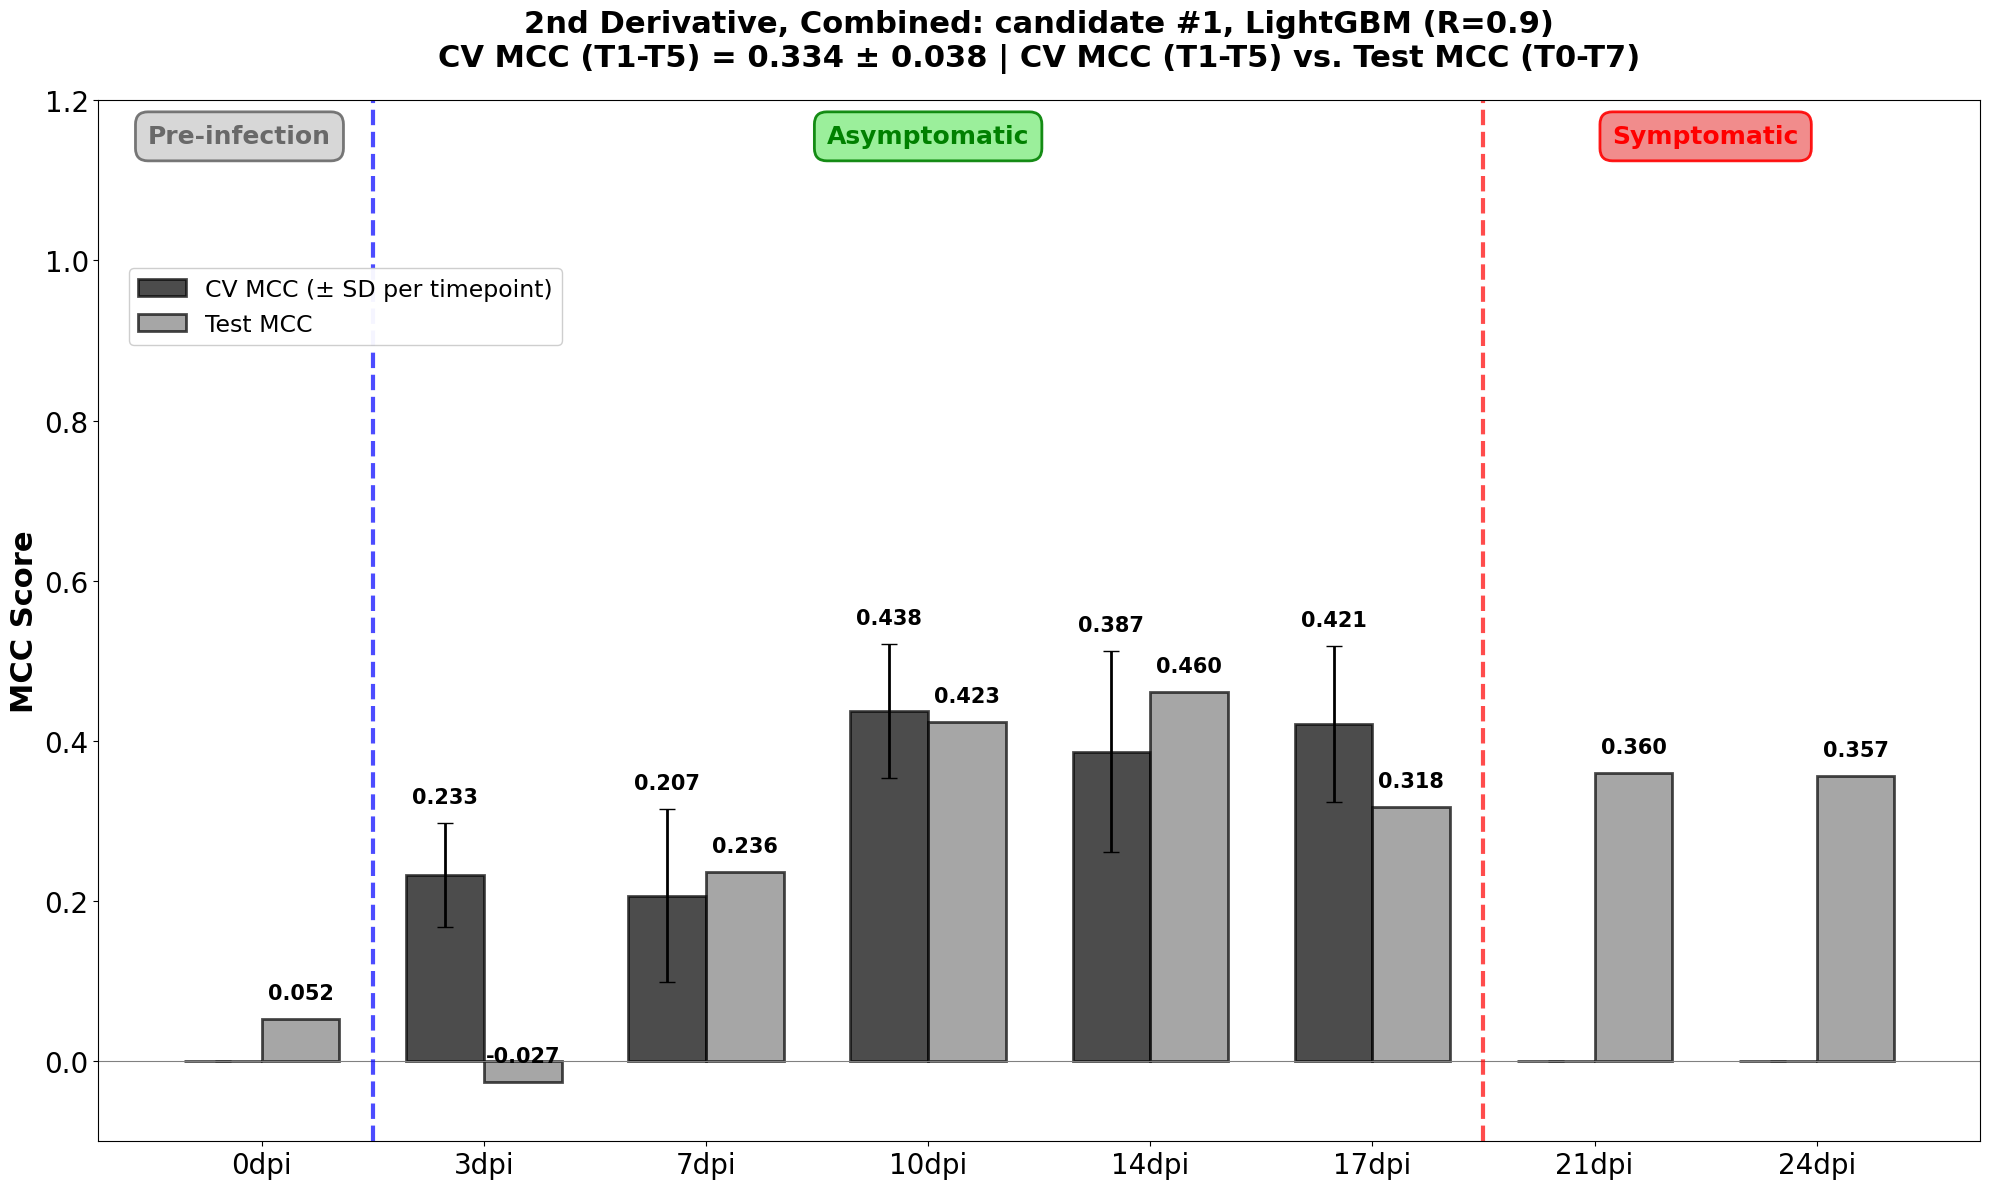


[2nd Derivative | Combined] Candidate #2: LDA (R=0.8), CV MCC (T1-T5) = 0.321 ± 0.055
Timepoint Display_Timepoint   CV_MCC  CV_MCC_Std  Test_MCC
       T0              0dpi      NaN         NaN  0.030240
       T1              3dpi 0.260336    0.102350  0.157895
       T2              7dpi 0.266322    0.099301  0.211662
       T3             10dpi 0.385899    0.160863  0.316228
       T4             14dpi 0.411908    0.079929  0.184274
       T5             17dpi 0.274318    0.070659  0.184274
       T6             21dpi      NaN         NaN  0.281815
       T7             24dpi      NaN         NaN  0.273767


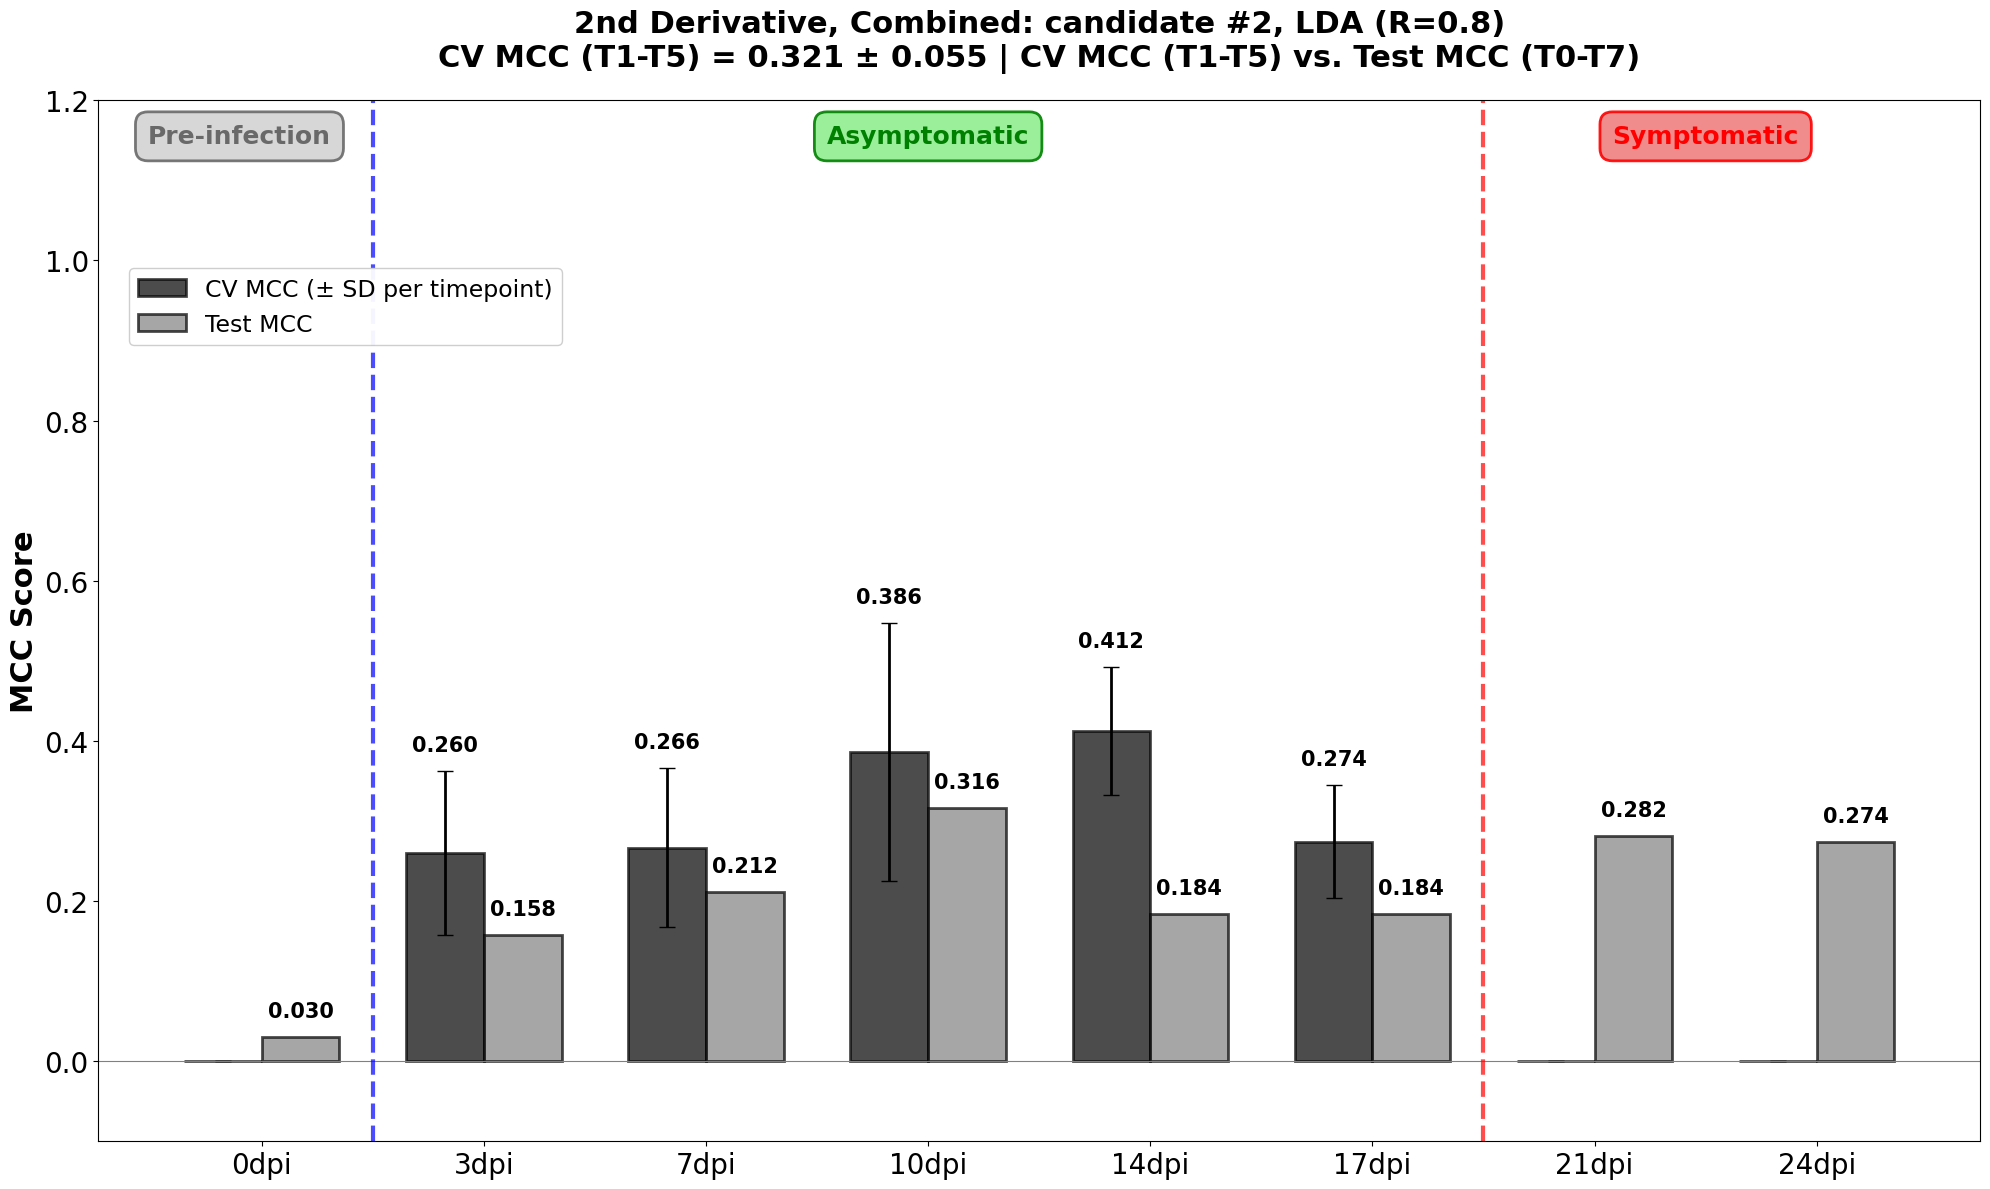


[2nd Derivative | Combined] Candidate #3: Logistic Regression (R=0.8), CV MCC (T1-T5) = 0.313 ± 0.074
Timepoint Display_Timepoint   CV_MCC  CV_MCC_Std  Test_MCC
       T0              0dpi      NaN         NaN  0.003170
       T1              3dpi 0.237922    0.057488  0.131625
       T2              7dpi 0.199447    0.090496  0.263579
       T3             10dpi 0.473466    0.179108  0.395973
       T4             14dpi 0.378320    0.140480  0.131991
       T5             17dpi 0.266941    0.069718  0.236924
       T6             21dpi      NaN         NaN  0.222907
       T7             24dpi      NaN         NaN  0.278351


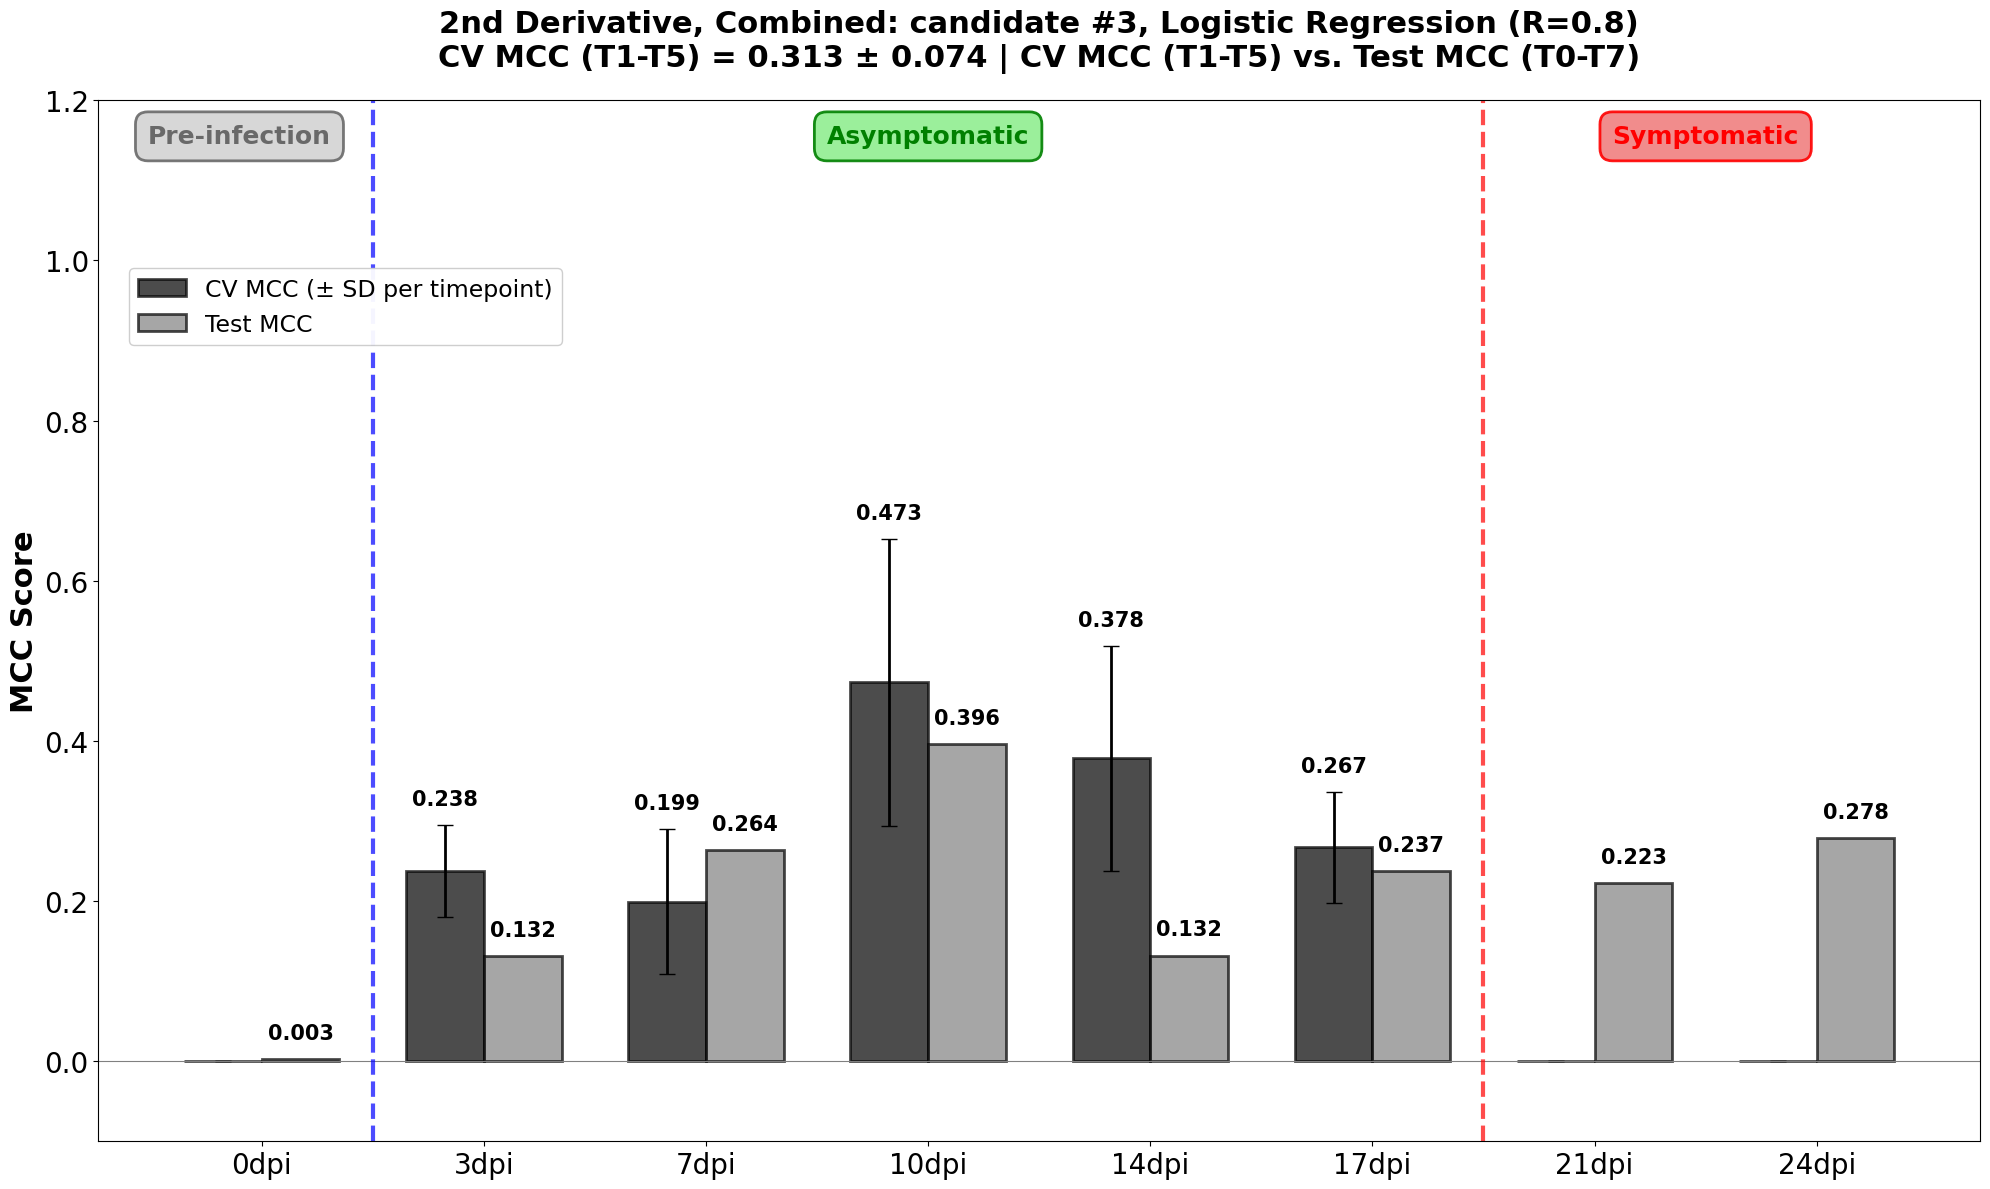


[2nd Derivative | Fingerprint] Candidate #1: LightGBM (R=0.7), CV MCC (T1-T5) = 0.384 ± 0.027
Timepoint Display_Timepoint   CV_MCC  CV_MCC_Std  Test_MCC
       T0              0dpi      NaN         NaN  0.030889
       T1              3dpi 0.278715    0.063634  0.131991
       T2              7dpi 0.332962    0.143250  0.367413
       T3             10dpi 0.447283    0.117313  0.448769
       T4             14dpi 0.392275    0.106238  0.394874
       T5             17dpi 0.482172    0.104821  0.474342
       T6             21dpi      NaN         NaN  0.357248
       T7             24dpi      NaN         NaN  0.304796


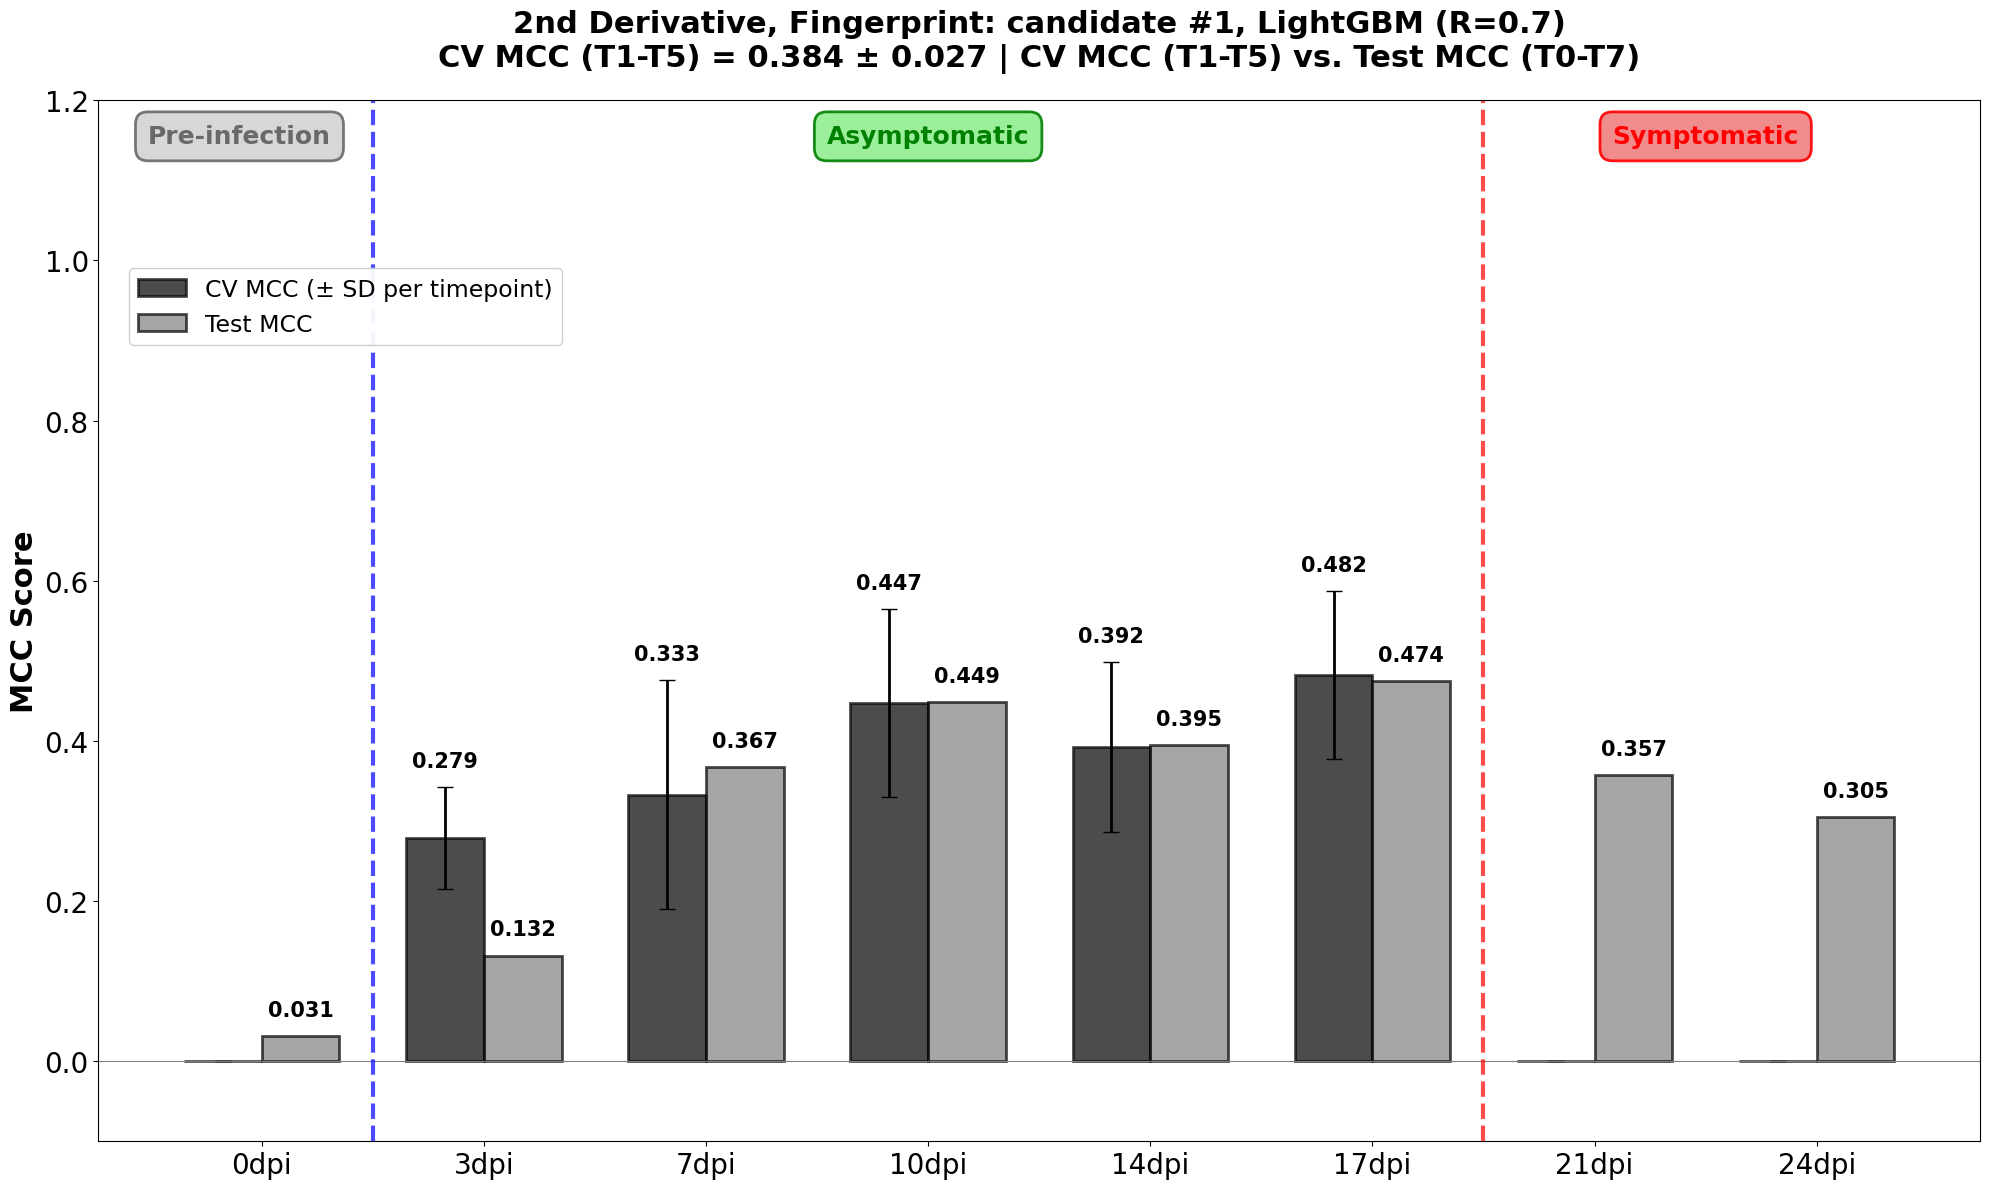


[2nd Derivative | Fingerprint] Candidate #2: XGBoost (R=0.6), CV MCC (T1-T5) = 0.380 ± 0.073
Timepoint Display_Timepoint   CV_MCC  CV_MCC_Std  Test_MCC
       T0              0dpi      NaN         NaN -0.016307
       T1              3dpi 0.304048    0.080427  0.131991
       T2              7dpi 0.380883    0.117421  0.236082
       T3             10dpi 0.453371    0.122506  0.504385
       T4             14dpi 0.382976    0.102397  0.395973
       T5             17dpi 0.392108    0.135042  0.473684
       T6             21dpi      NaN         NaN  0.350713
       T7             24dpi      NaN         NaN  0.336384


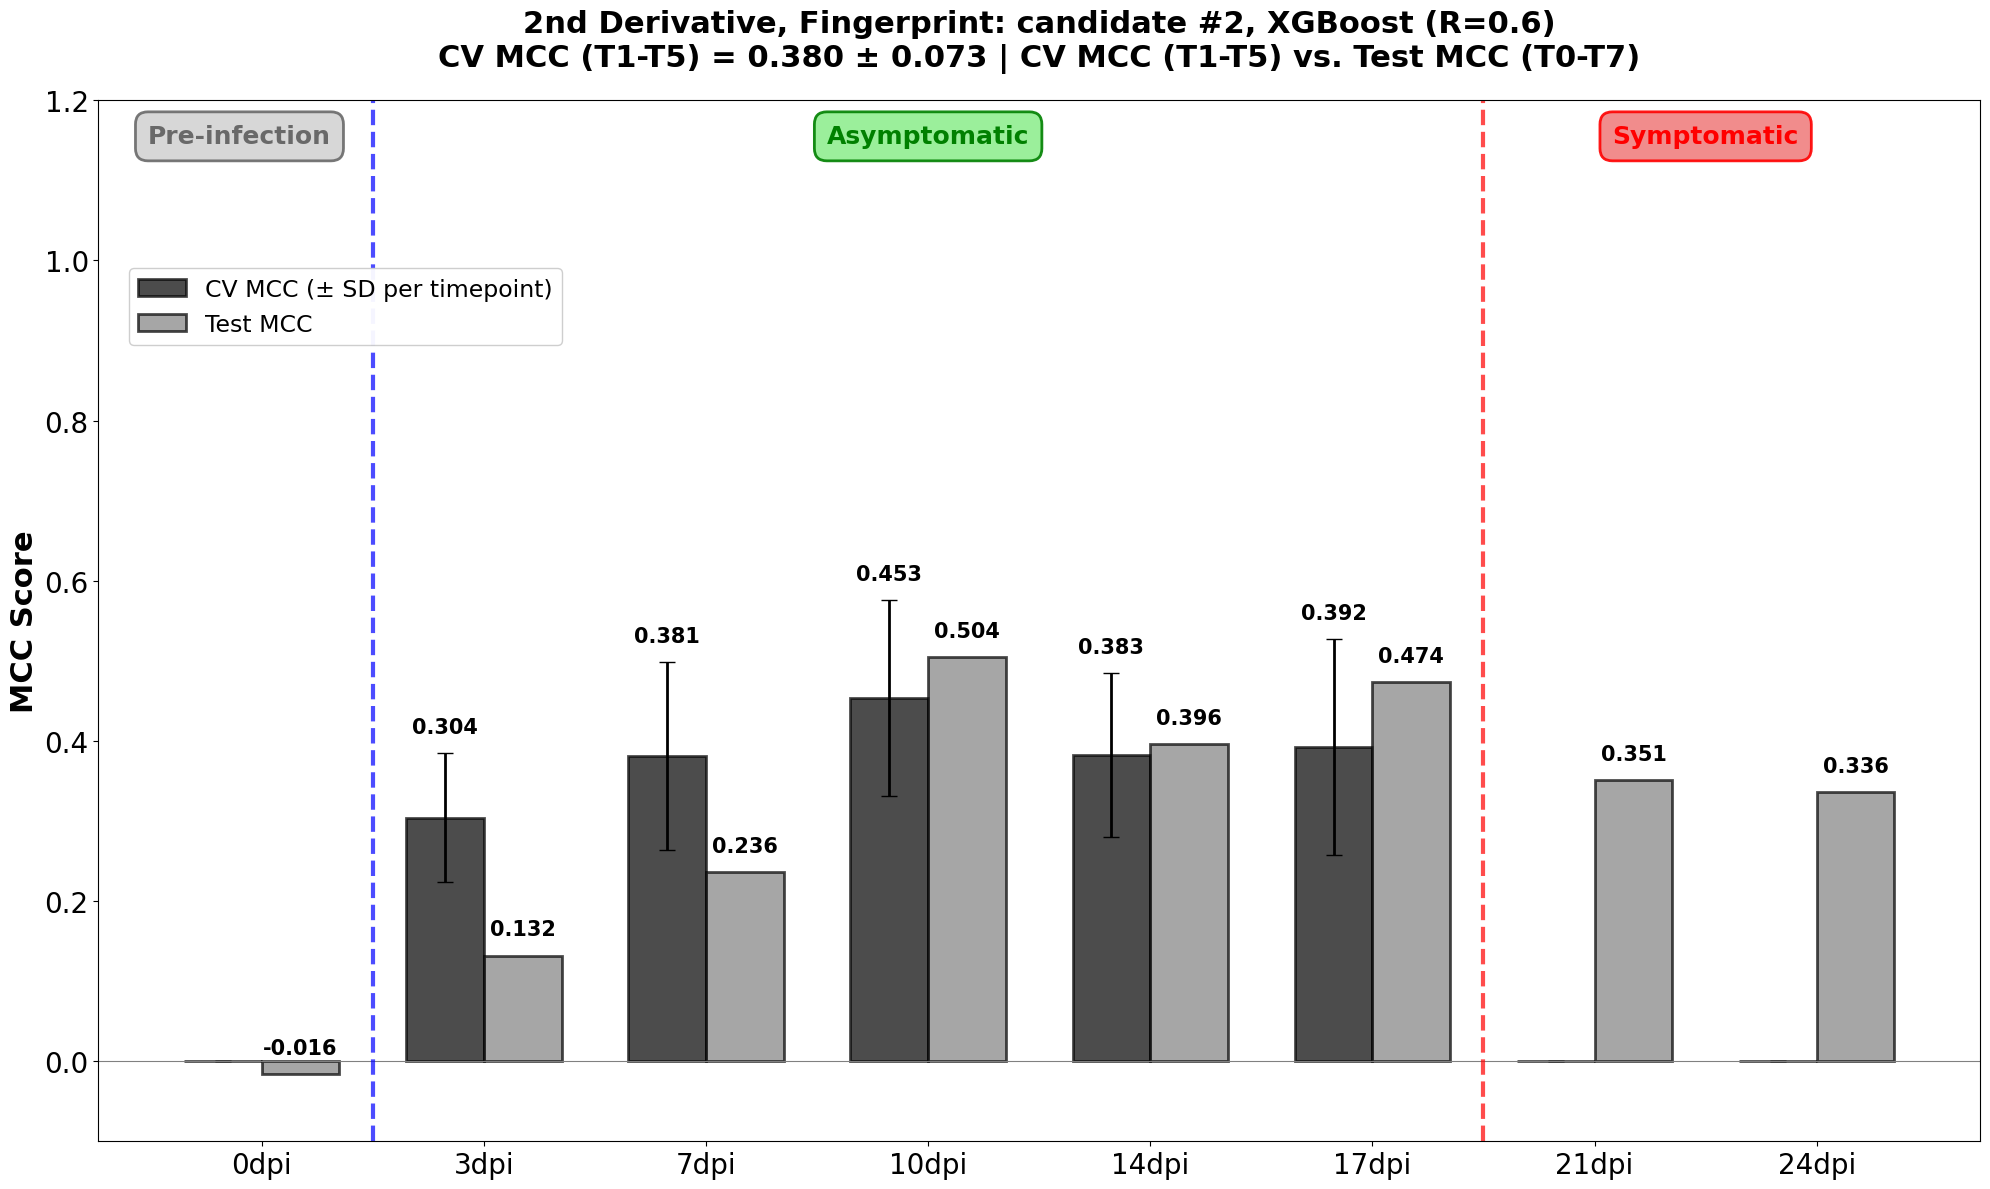


[2nd Derivative | Fingerprint] Candidate #3: XGBoost (R=0.9), CV MCC (T1-T5) = 0.373 ± 0.057
Timepoint Display_Timepoint   CV_MCC  CV_MCC_Std  Test_MCC
       T0              0dpi      NaN         NaN  0.052153
       T1              3dpi 0.276813    0.050624  0.000000
       T2              7dpi 0.354739    0.181792  0.054216
       T3             10dpi 0.414525    0.099617  0.476331
       T4             14dpi 0.425089    0.160872  0.398199
       T5             17dpi 0.400713    0.148084  0.395973
       T6             21dpi      NaN         NaN  0.415717
       T7             24dpi      NaN         NaN  0.300332


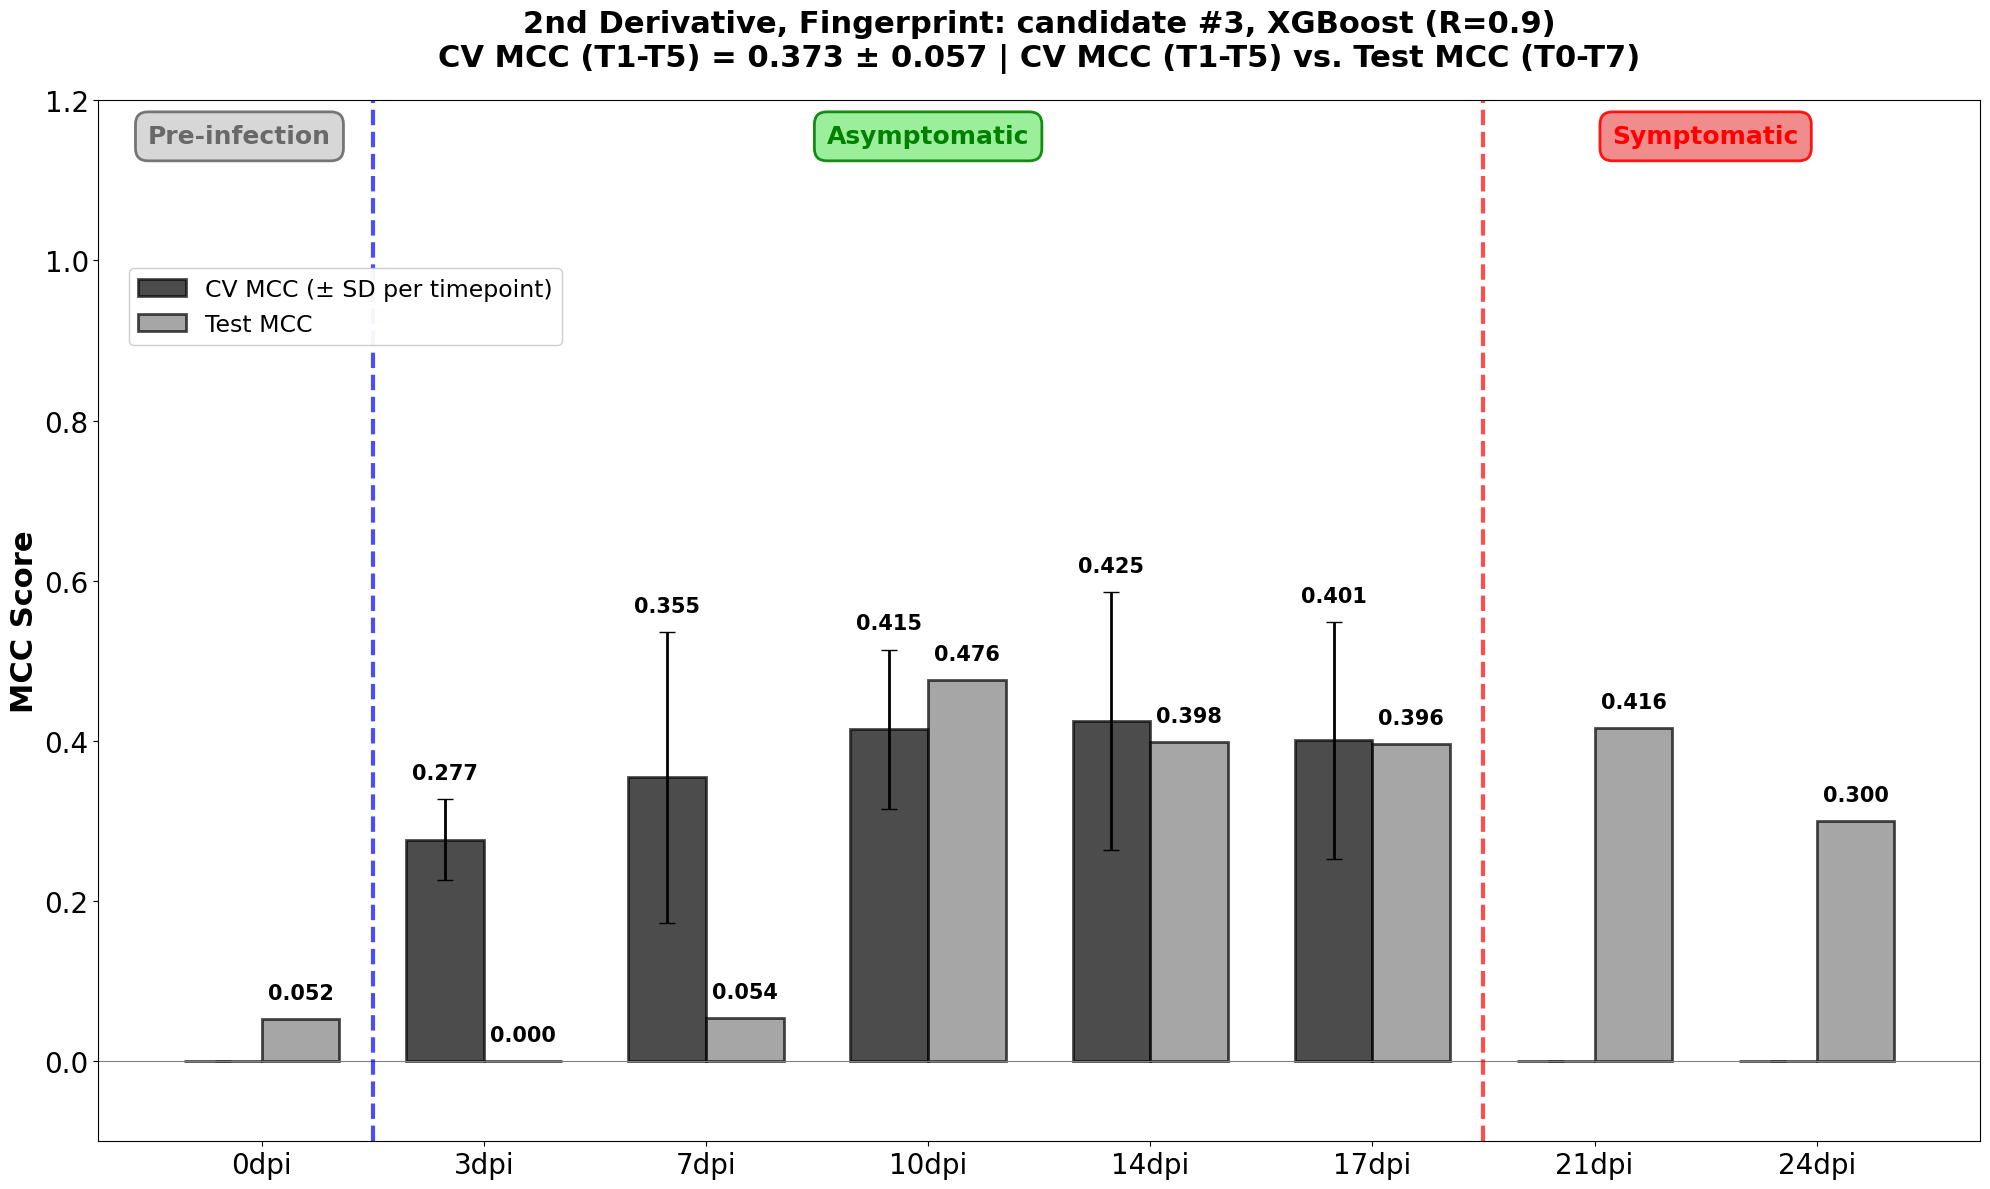


[2nd Derivative | Stretching] Candidate #1: Logistic Regression (R=0.9), CV MCC (T1-T5) = 0.229 ± 0.012
Timepoint Display_Timepoint   CV_MCC  CV_MCC_Std  Test_MCC
       T0              0dpi      NaN         NaN  0.021280
       T1              3dpi 0.198727    0.122247  0.236924
       T2              7dpi 0.188971    0.093780  0.128947
       T3             10dpi 0.264263    0.163341  0.131991
       T4             14dpi 0.258401    0.154388 -0.105409
       T5             17dpi 0.230202    0.094870  0.131625
       T6             21dpi      NaN         NaN  0.099375
       T7             24dpi      NaN         NaN  0.149746


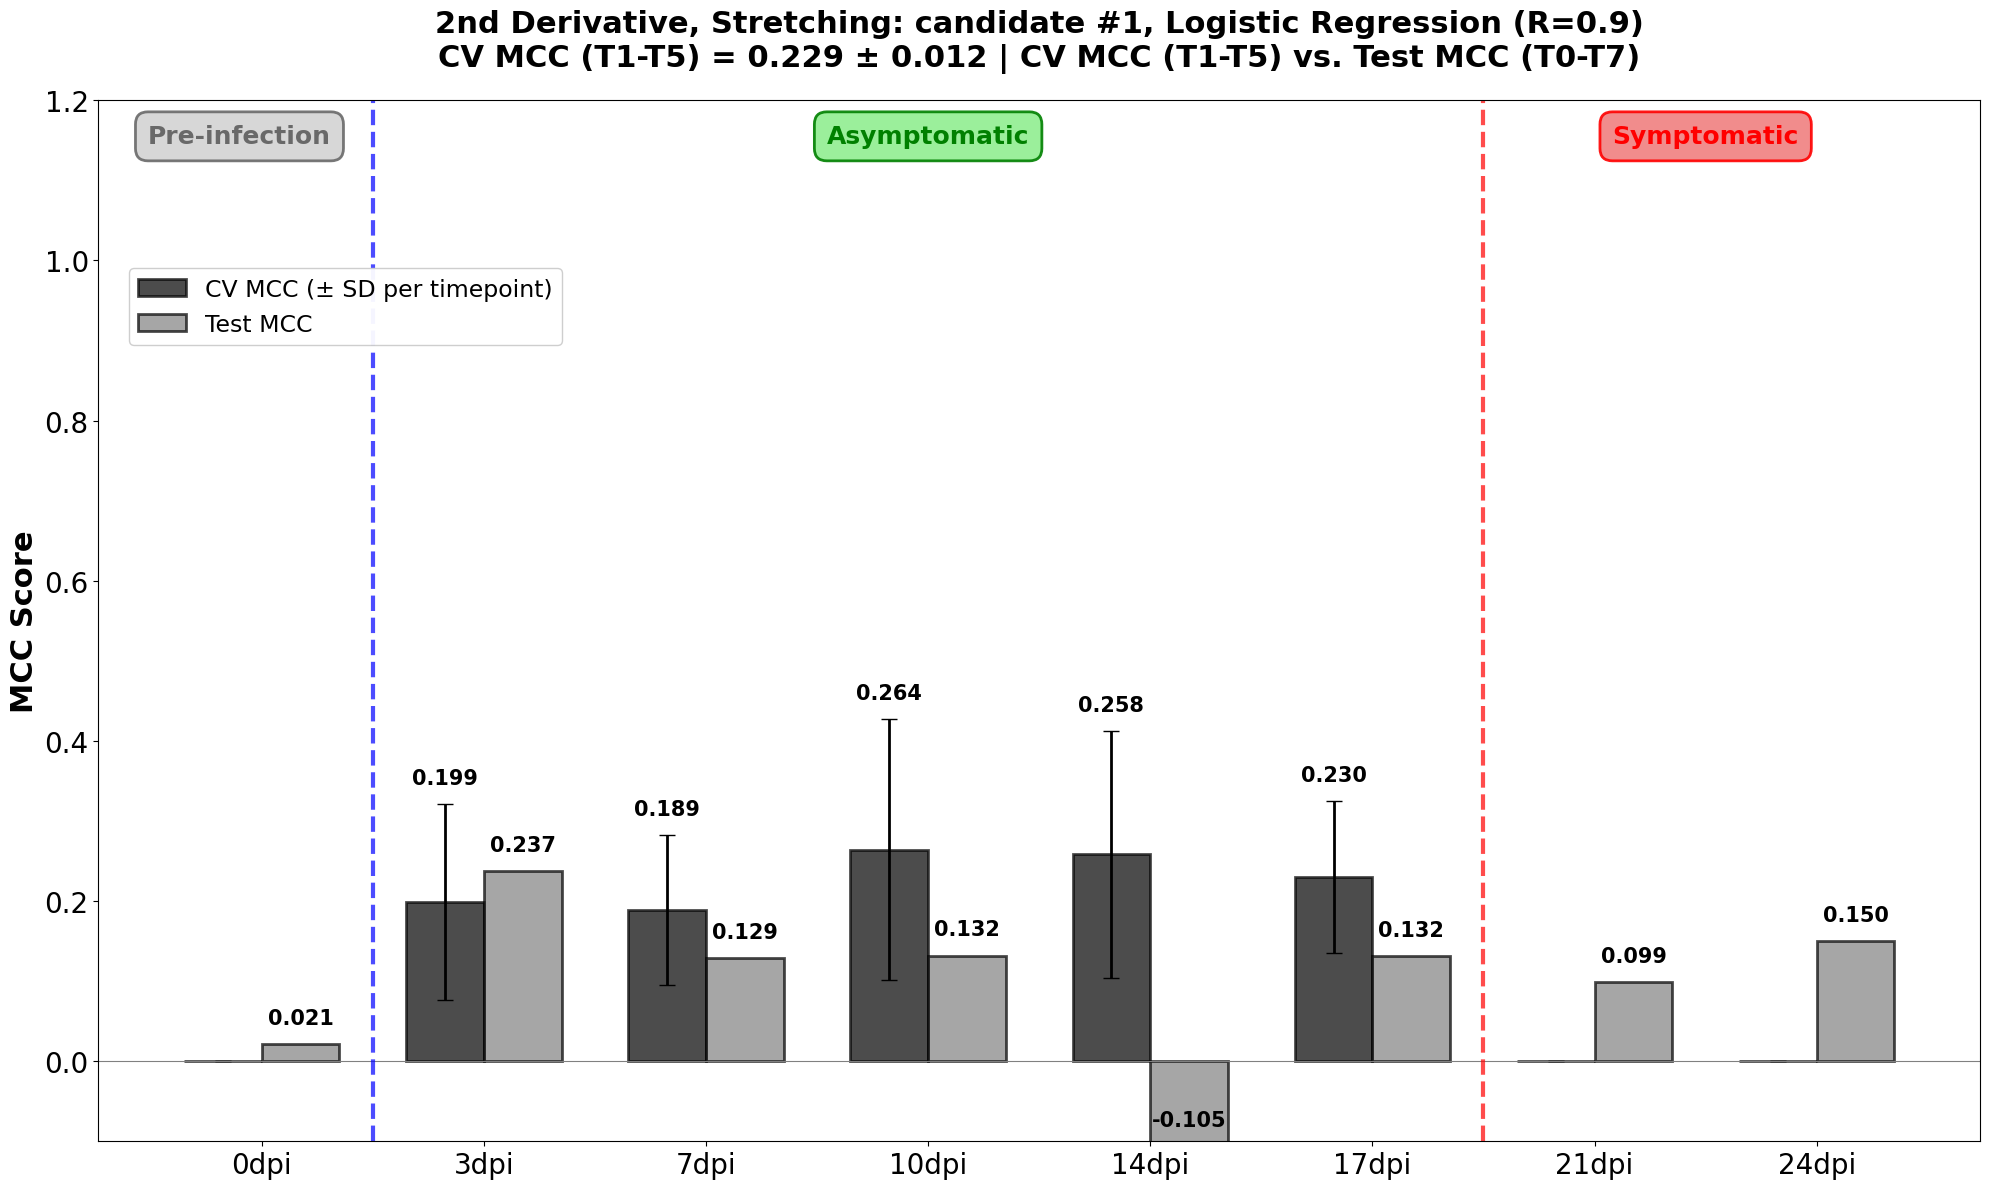


[2nd Derivative | Stretching] Candidate #2: LDA (R=1.0), CV MCC (T1-T5) = 0.216 ± 0.027
Timepoint Display_Timepoint   CV_MCC  CV_MCC_Std  Test_MCC
       T0              0dpi      NaN         NaN  0.127053
       T1              3dpi 0.178425    0.115864  0.000000
       T2              7dpi 0.175346    0.120542  0.130607
       T3             10dpi 0.292206    0.119994  0.316228
       T4             14dpi 0.299668    0.133320 -0.026398
       T5             17dpi 0.132181    0.108357  0.133870
       T6             21dpi      NaN         NaN  0.172716
       T7             24dpi      NaN         NaN  0.121029


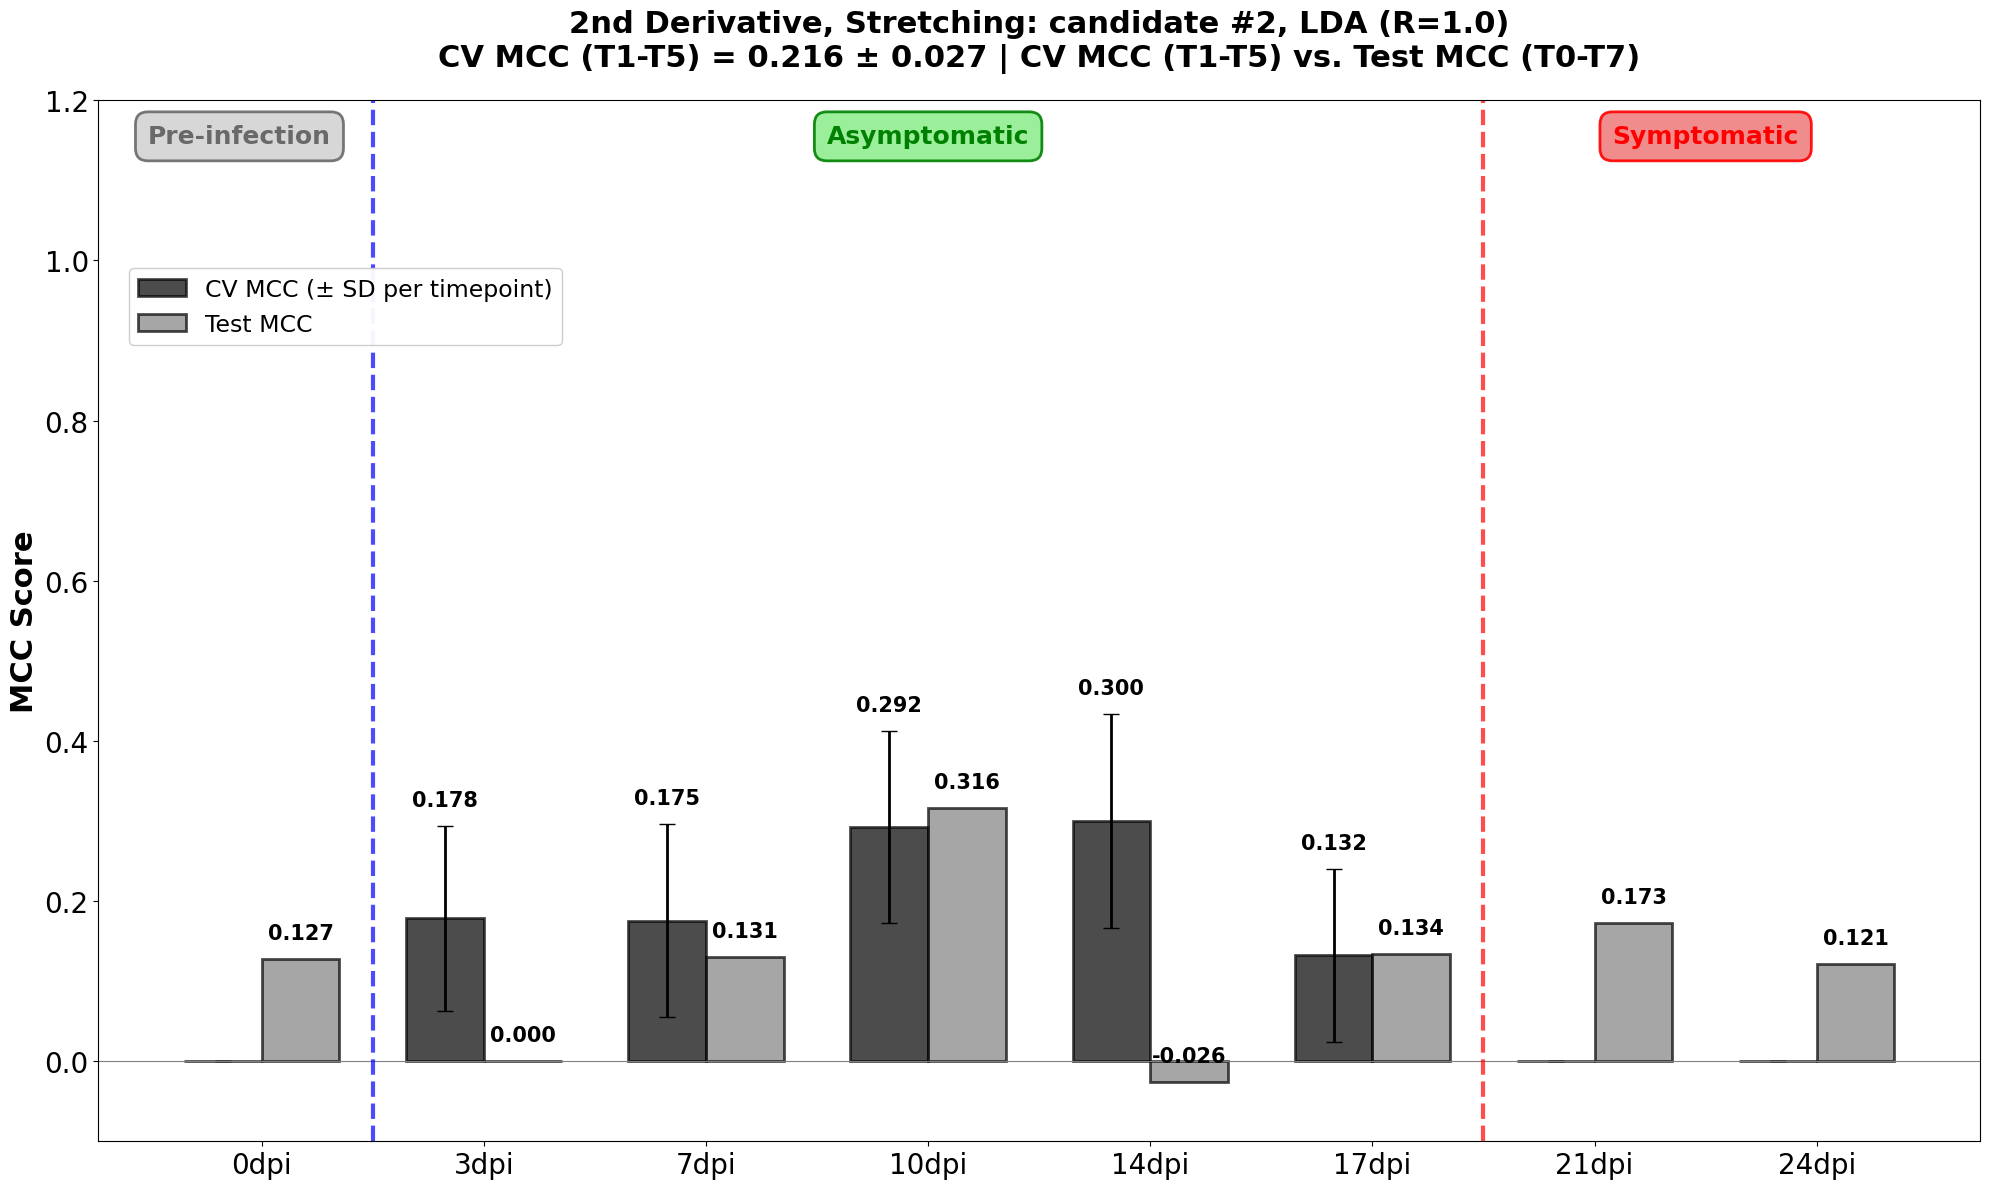


[2nd Derivative | Stretching] Candidate #3: Logistic Regression (R=1.0), CV MCC (T1-T5) = 0.214 ± 0.025
Timepoint Display_Timepoint   CV_MCC  CV_MCC_Std  Test_MCC
       T0              0dpi      NaN         NaN  0.016307
       T1              3dpi 0.154099    0.106919  0.184787
       T2              7dpi 0.181017    0.116643  0.079156
       T3             10dpi 0.259033    0.166864  0.238919
       T4             14dpi 0.292326    0.138165 -0.079195
       T5             17dpi 0.177066    0.107751  0.185826
       T6             21dpi      NaN         NaN  0.109831
       T7             24dpi      NaN         NaN  0.149746


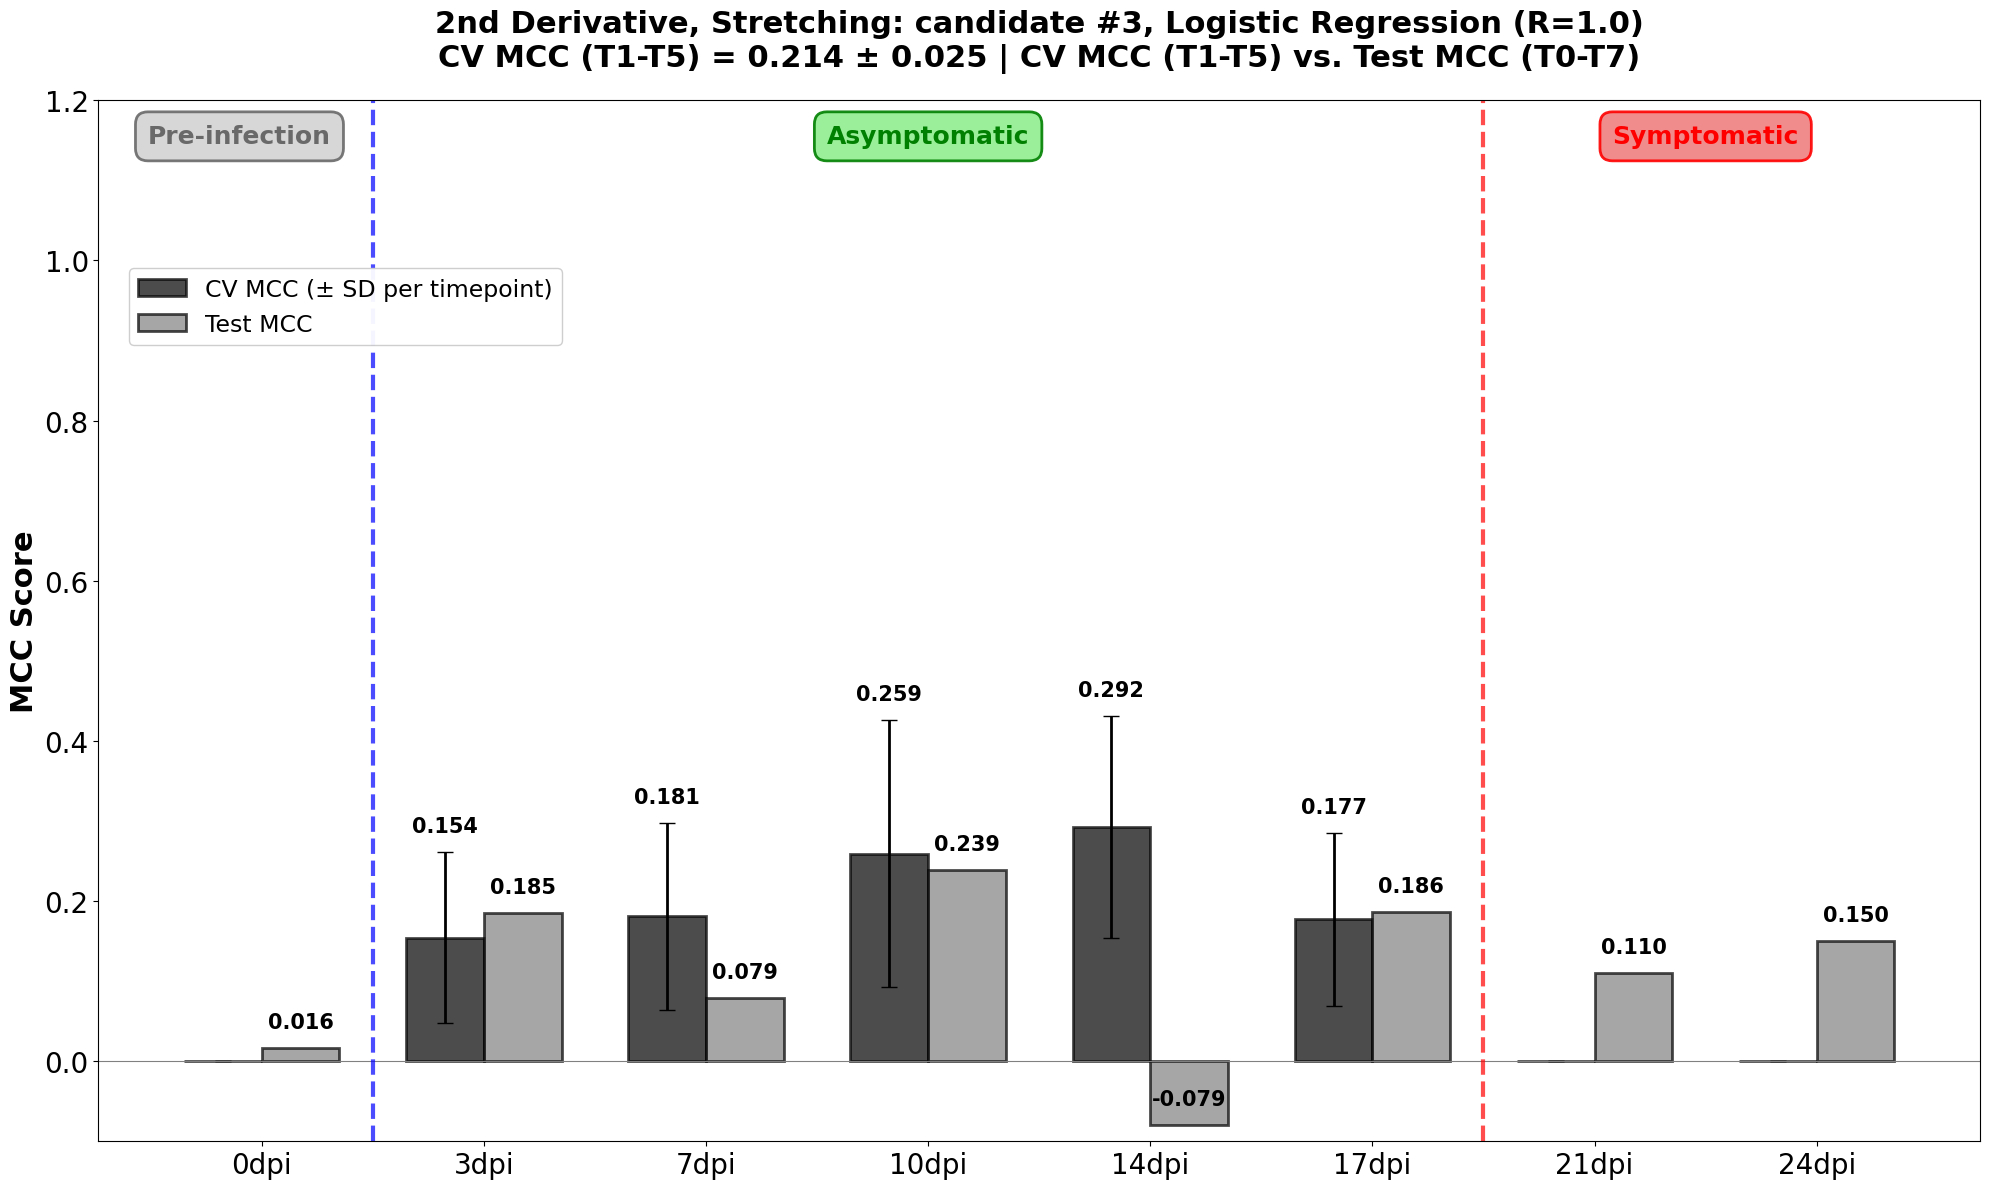

CPU times: total: 17.9 s
Wall time: 18 s


In [14]:
%%time
def build_winning_profile_region(cv_per_timepoint_region_df, all_models_test_metrics_region_df,
                                 cand_R, cand_model, timepoints_region_order):
    rows = []
    for tp in timepoints_region_order:
        cv_sub = cv_per_timepoint_region_df[(cv_per_timepoint_region_df['R_value'] == cand_R) &
                                            (cv_per_timepoint_region_df['Model'] == cand_model) &
                                            (cv_per_timepoint_region_df['Timepoint'] == tp)]
        test_sub = all_models_test_metrics_region_df[
            (all_models_test_metrics_region_df['R_value'] == cand_R) &
            (all_models_test_metrics_region_df['Model'] == cand_model) &
            (all_models_test_metrics_region_df['Timepoint'] == tp)]
        rows.append({
            'Timepoint': tp,
            'Display_Timepoint': convert_timepoint(tp),
            'CV_MCC': cv_sub['CV_MCC_OOF'].mean() if not cv_sub.empty else np.nan,
            'CV_MCC_Std': cv_sub['CV_MCC_OOF_Std'].mean() if not cv_sub.empty else np.nan,
            'Test_MCC': test_sub['Test MCC'].mean() if not test_sub.empty else np.nan,
        })
    return pd.DataFrame(rows)


def plot_candidate_profile_region(profile_df, cand_R, cand_model, rank, region_name,
                                  cv_mcc_t1t5, cv_mcc_std_t1t5, spectrum_type_name):
    FONT_SIZES = {'title': 22, 'axis_label': 22, 'axis_ticks': 20,
                  'bar_values': 15, 'legend': 17, 'section_labels': 18}

    fig, ax = plt.subplots(figsize=(20, 12))
    x = np.arange(len(profile_df))
    width = 0.35

    cv_heights = profile_df['CV_MCC'].fillna(0)
    test_heights = profile_df['Test_MCC'].fillna(0)
    cv_yerr = np.array([std_val if (not np.isnan(val) and not np.isnan(std_val)) else 0.0
                        for val, std_val in zip(profile_df['CV_MCC'], profile_df['CV_MCC_Std'])])

    bars_cv = ax.bar(x - width / 2, cv_heights, width, yerr=cv_yerr, capsize=6,
                     error_kw={'elinewidth': 2, 'ecolor': 'black'},
                     label='CV MCC (± SD per timepoint)',
                     color='#000000', alpha=0.7, edgecolor='black', linewidth=2)
    bars_test = ax.bar(x + width / 2, test_heights, width,
                       label='Test MCC',
                       color='#808080', alpha=0.7, edgecolor='black', linewidth=2)

    for bar, val, err in zip(bars_cv, profile_df['CV_MCC'], cv_yerr):
        if not np.isnan(val):
            ax.text(bar.get_x() + bar.get_width() / 2., bar.get_height() + err + 0.02,
                    f'{val:.3f}', ha='center', va='bottom',
                    fontsize=FONT_SIZES['bar_values'], fontweight='bold')
    for bar, val in zip(bars_test, profile_df['Test_MCC']):
        if not np.isnan(val):
            ax.text(bar.get_x() + bar.get_width() / 2., bar.get_height() + 0.02,
                    f'{val:.3f}', ha='center', va='bottom',
                    fontsize=FONT_SIZES['bar_values'], fontweight='bold')

    ax.set_xticks(x)
    ax.set_xticklabels(profile_df['Display_Timepoint'],
                       fontsize=FONT_SIZES['axis_ticks'], rotation=0, ha='center')
    ax.set_ylabel('MCC Score', fontsize=FONT_SIZES['axis_label'], fontweight='bold')
    ax.set_title(f'{spectrum_type_name}, {region_name}: candidate #{rank}, {cand_model} (R={cand_R})\n'
                 f'CV MCC (T1-T5) = {cv_mcc_t1t5:.3f} ± {cv_mcc_std_t1t5:.3f} | '
                 f'CV MCC (T1-T5) vs. Test MCC (T0-T7)',
                 fontsize=FONT_SIZES['title'], fontweight='bold', pad=25)
    ax.tick_params(axis='y', labelsize=FONT_SIZES['axis_ticks'])
    ax.axhline(0, color='grey', linewidth=0.8)
    ax.legend(fontsize=FONT_SIZES['legend'], loc='upper left', framealpha=0.95,
              bbox_to_anchor=(0.01, 0.85))
    ax.set_ylim(-0.1, 1.2)

    position_of = {row['Timepoint']: idx for idx, row in profile_df.iterrows()}

    # label, first timepoint, last timepoint, x shift, text colour, box colour
    phase_boxes = [
        ('Pre-infection', 'T0', 'T0', -0.1, 'dimgrey', 'lightgrey'),
        ('Asymptomatic', 'T1', 'T5', 0, 'green', 'lightgreen'),
        ('Symptomatic', 'T6', 'T7', 0, 'red', 'lightcoral'),
    ]
    for label, first, last, shift, text_color, box_color in phase_boxes:
        if first in position_of and last in position_of:
            center = (position_of[first] + position_of[last]) / 2 + shift
            ax.text(center, 1.17, label,
                    ha='center', va='top', fontsize=FONT_SIZES['section_labels'],
                    fontweight='bold', color=text_color,
                    bbox=dict(boxstyle='round,pad=0.5', facecolor=box_color,
                              alpha=0.9, edgecolor=text_color, linewidth=2))

    if 'T5' in position_of and 'T6' in position_of:
        ax.axvline(x=(position_of['T5'] + position_of['T6']) / 2,
                   color='red', linestyle='--', alpha=0.7, linewidth=3)
    if 'T0' in position_of and 'T1' in position_of:
        ax.axvline(x=(position_of['T0'] + position_of['T1']) / 2,
                   color='blue', linestyle='--', alpha=0.7, linewidth=3)

    plt.tight_layout()
    spectrum_tag = spectrum_type_name.replace(' ', '')
    fname = f'{spectrum_tag}_{region_name}_Candidate{rank}_{cand_model}_R{cand_R}_Profile_T0T7.png'.replace(' ', '_')
    plt.savefig(os.path.join(OUTPUT_DIR, fname), dpi=150)
    plt.show()


region_top3_profiles_by_type = {}

for spectrum_type_name in spectrum_type_names:
    region_top3_profiles = {}

    for region_name in region_names:
        cv_per_timepoint_region_df = results[spectrum_type_name][region_name]['cv_per_timepoint_df']
        all_models_test_metrics_region_df = results[spectrum_type_name][region_name]['all_models_test_metrics_df']
        top3 = region_top3_by_type[spectrum_type_name][region_name]

        profiles = []
        for rank, cand_row in top3.iterrows():
            cand_R = cand_row['R_value']
            cand_model = cand_row['Model']
            cand_std = cand_row['Std_CV_MCC_Pooled_T1T5']

            profile_df = build_winning_profile_region(
                cv_per_timepoint_region_df, all_models_test_metrics_region_df,
                cand_R, cand_model, ALL_TIMEPOINTS)
            profile_df.insert(0, 'Spectrum_Type', spectrum_type_name)
            profile_df.insert(1, 'Region', region_name)
            profile_df.insert(2, 'Rank', rank + 1)
            profile_df.insert(3, 'R_value', cand_R)
            profile_df.insert(4, 'Model', cand_model)
            profiles.append(profile_df)

            print(f"\n[{spectrum_type_name} | {region_name}] Candidate #{rank + 1}: {cand_model} (R={cand_R}), "
                  f"CV MCC (T1-T5) = {cand_row['Mean_CV_MCC_Pooled_T1T5']:.3f} ± {cand_std:.3f}")
            print(profile_df.drop(columns=['Spectrum_Type', 'Region', 'Rank', 'R_value', 'Model']).to_string(index=False))

            plot_candidate_profile_region(profile_df, cand_R, cand_model, rank + 1, region_name,
                                          cand_row['Mean_CV_MCC_Pooled_T1T5'], cand_std, spectrum_type_name)

        region_top3_profiles[region_name] = pd.concat(profiles, ignore_index=True)

    spectrum_tag = spectrum_type_name.replace(' ', '')
    spectrum_profile_df = pd.concat(region_top3_profiles.values(), ignore_index=True)
    spectrum_profile_df.to_csv(
        os.path.join(OUTPUT_DIR, f'Region_Comparison_Top3_Candidates_Profile_T0T7_{spectrum_tag}.csv'), index=False)
    region_top3_profiles_by_type[spectrum_type_name] = region_top3_profiles

all_regions_all_types_top3_profile_df = pd.concat(
    [pd.concat(region_top3_profiles_by_type[st].values(), ignore_index=True) for st in spectrum_type_names],
    ignore_index=True)
all_regions_all_types_top3_profile_df.to_csv(
    os.path.join(OUTPUT_DIR, 'Region_Comparison_Top3_Candidates_Profile_T0T7_AllSpectrumTypes.csv'), index=False)